# DAY 3 — RESEARCH ANALYSIS

## Research Topic
Resource-Efficient Small Language Models using Knowledge Distillation

## Research Question
Can knowledge distillation improve the task performance of a
small language model compared with conventional fine-tuning,
while retaining its efficiency advantages?

## Task
Sentiment Classification

## Dataset
SST-2

## Experiments

E0 — Teacher
E1 — Baseline Student
E2 — KD Student

## Day 3 Objective

1. Verify saved experiments.
2. Compare Teacher, Baseline Student, and KD Student.
3. Analyze parameter efficiency.
4. Measure model storage.
5. Compare training cost.
6. Measure inference latency and throughput.
7. Analyze GPU memory where reliable.
8. Generate predictions.
9. Generate confusion matrices.
10. Perform error analysis.
11. Measure teacher-student agreement.
12. Perform controlled ablation if feasible.
13. Review relevant literature.
14. Refine the research gap.
15. Prepare evidence for the final paper.

In [ ]:
import torch

print("====================================")
print("DAY 3 SYSTEM CHECK")
print("====================================")

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU is NOT available")

DAY 3 SYSTEM CHECK
PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [ ]:
import os

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"

print("====================================")
print("DAY 3 PROJECT FILE CHECK")
print("====================================")

print("Project exists:", os.path.exists(PROJECT_ROOT))
print("Project path:", PROJECT_ROOT)

print("\n--- MODELS ---")
print("Baseline checkpoint:",
      os.path.exists(f"{PROJECT_ROOT}/models/baseline_student/final"))

print("KD checkpoint:",
      os.path.exists(f"{PROJECT_ROOT}/models/kd/student_epoch3"))

print("\n--- RESULTS ---")
print("Baseline results:",
      os.path.exists(f"{PROJECT_ROOT}/results/baseline_results.json"))

print("KD results:",
      os.path.exists(f"{PROJECT_ROOT}/results/kd_results.json"))

print("Baseline history:",
      os.path.exists(f"{PROJECT_ROOT}/results/baseline_training_history.json"))

print("KD history:",
      os.path.exists(f"{PROJECT_ROOT}/results/kd_training_history.json"))

DAY 3 PROJECT FILE CHECK
Project exists: False
Project path: /content/drive/MyDrive/SLM_KD_Research

--- MODELS ---
Baseline checkpoint: False
KD checkpoint: False

--- RESULTS ---
Baseline results: False
KD results: False
Baseline history: False
KD history: False


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"

print("====================================")
print("DAY 1 + DAY 2 RECOVERY CHECK")
print("====================================")

print("Project exists:", os.path.exists(PROJECT_ROOT))

if os.path.exists(PROJECT_ROOT):
    print("\nProject contents:")
    for item in os.listdir(PROJECT_ROOT):
        print(" -", item)

print("\n--- MODELS ---")
print("Baseline checkpoint:",
      os.path.exists(f"{PROJECT_ROOT}/models/baseline_student/final"))

print("KD checkpoint:",
      os.path.exists(f"{PROJECT_ROOT}/models/kd/student_epoch3"))

print("\n--- RESULTS ---")
print("Baseline results:",
      os.path.exists(f"{PROJECT_ROOT}/results/baseline_results.json"))

print("KD results:",
      os.path.exists(f"{PROJECT_ROOT}/results/kd_results.json"))

print("Baseline history:",
      os.path.exists(f"{PROJECT_ROOT}/results/baseline_training_history.json"))

print("KD history:",
      os.path.exists(f"{PROJECT_ROOT}/results/kd_training_history.json"))

DAY 1 + DAY 2 RECOVERY CHECK
Project exists: True

Project contents:
 - data
 - models
 - results
 - logs
 - notebooks

--- MODELS ---
Baseline checkpoint: True
KD checkpoint: True

--- RESULTS ---
Baseline results: True
KD results: True
Baseline history: False
KD history: True


In [ ]:
import os

RESULTS_DIR = "/content/drive/MyDrive/SLM_KD_Research/results"

print("====================================")
print("RESULTS DIRECTORY CHECK")
print("====================================")

for filename in sorted(os.listdir(RESULTS_DIR)):
    path = os.path.join(RESULTS_DIR, filename)

    if os.path.isfile(path):
        size_kb = os.path.getsize(path) / 1024
        print(f"{filename}  |  {size_kb:.2f} KB")

RESULTS DIRECTORY CHECK
baseline_results.json  |  0.44 KB
kd_results.json  |  0.54 KB
kd_training_history.json  |  0.58 KB


In [ ]:
import json
import os

RESULTS_DIR = "/content/drive/MyDrive/SLM_KD_Research/results"

print("====================================")
print("SAVED RESEARCH RESULTS")
print("====================================")

for filename in ["baseline_results.json", "kd_results.json"]:
    path = os.path.join(RESULTS_DIR, filename)

    print(f"\n===== {filename} =====")

    with open(path, "r") as f:
        data = json.load(f)

    for key, value in data.items():
        print(f"{key}: {value}")

SAVED RESEARCH RESULTS

===== baseline_results.json =====
experiment: E1_baseline_student
student_model: google/bert_uncased_L-2_H-128_A-2
dataset: SST-2
split: validation
validation_samples: 872
max_length: 128
batch_size: 16
learning_rate: 2e-05
epochs: 3
seed: 42
total_parameters: 4386178
validation_loss: 0.4271568989211863
validation_accuracy: 0.8291284403669725
validation_f1: 0.826945412311266

===== kd_results.json =====
experiment: E2_KD_student
teacher_model: textattack/bert-base-uncased-SST-2
student_model: google/bert_uncased_L-2_H-128_A-2
dataset: SST-2
split: validation
validation_samples: 872
max_length: 128
batch_size: 16
learning_rate: 2e-05
epochs: 3
temperature: 2.0
alpha: 0.5
seed: 42
total_parameters: 4386178
validation_loss: 0.5380656463856047
validation_accuracy: 0.8188073394495413
validation_f1: 0.8297413793103449


In [ ]:
import json
import os

RESULTS_DIR = "/content/drive/MyDrive/SLM_KD_Research/results"

with open(os.path.join(RESULTS_DIR, "baseline_results.json"), "r") as f:
    baseline = json.load(f)

with open(os.path.join(RESULTS_DIR, "kd_results.json"), "r") as f:
    kd = json.load(f)

accuracy_difference = kd["validation_accuracy"] - baseline["validation_accuracy"]
f1_difference = kd["validation_f1"] - baseline["validation_f1"]

print("====================================")
print("BASELINE vs KD — FIRST COMPARISON")
print("====================================")

print(f"Baseline Accuracy : {baseline['validation_accuracy']:.6f}")
print(f"KD Accuracy       : {kd['validation_accuracy']:.6f}")
print(f"Accuracy Difference: {accuracy_difference:.6f}")

print()

print(f"Baseline F1       : {baseline['validation_f1']:.6f}")
print(f"KD F1             : {kd['validation_f1']:.6f}")
print(f"F1 Difference    : {f1_difference:.6f}")

print()

print("Percentage-point differences:")
print(f"Accuracy: {accuracy_difference * 100:.4f} pp")
print(f"F1      : {f1_difference * 100:.4f} pp")

BASELINE vs KD — FIRST COMPARISON
Baseline Accuracy : 0.829128
KD Accuracy       : 0.818807
Accuracy Difference: -0.010321

Baseline F1       : 0.826945
KD F1             : 0.829741
F1 Difference    : 0.002796

Percentage-point differences:
Accuracy: -1.0321 pp
F1      : 0.2796 pp


In [ ]:
teacher_params = 109_483_778
student_params = 4_386_178

parameter_reduction = teacher_params - student_params
reduction_percent = (parameter_reduction / teacher_params) * 100
teacher_student_ratio = teacher_params / student_params

print("====================================")
print("MODEL SIZE / PARAMETER EFFICIENCY")
print("====================================")

print(f"Teacher parameters : {teacher_params:,}")
print(f"Student parameters : {student_params:,}")

print(f"\nParameter reduction: {parameter_reduction:,}")
print(f"Reduction percent  : {reduction_percent:.2f}%")
print(f"Teacher/Student ratio: {teacher_student_ratio:.2f}x")

MODEL SIZE / PARAMETER EFFICIENCY
Teacher parameters : 109,483,778
Student parameters : 4,386,178

Parameter reduction: 105,097,600
Reduction percent  : 95.99%
Teacher/Student ratio: 24.96x


In [ ]:
import csv
import os

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"
RESULTS_DIR = f"{PROJECT_ROOT}/results"

master_results_path = f"{RESULTS_DIR}/master_results.csv"

teacher_params = 109_483_778
student_params = 4_386_178

rows = [
    {
        "experiment": "E0_teacher",
        "model": "textattack/bert-base-uncased-SST-2",
        "parameters": teacher_params,
        "validation_accuracy": 0.9243119266055045,
        "validation_f1": 0.9263392857142857
    },
    {
        "experiment": "E1_baseline_student",
        "model": "google/bert_uncased_L-2_H-128_A-2",
        "parameters": student_params,
        "validation_accuracy": 0.8291284403669725,
        "validation_f1": 0.826945412311266
    },
    {
        "experiment": "E2_KD_student",
        "model": "google/bert_uncased_L-2_H-128_A-2",
        "parameters": student_params,
        "validation_accuracy": 0.8188073394495413,
        "validation_f1": 0.8297413793103449
    }
]

with open(master_results_path, "w", newline="") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=[
            "experiment",
            "model",
            "parameters",
            "validation_accuracy",
            "validation_f1"
        ]
    )
    writer.writeheader()
    writer.writerows(rows)

print("====================================")
print("MASTER RESULTS SAVED")
print("====================================")
print("File:", master_results_path)
print("Exists:", os.path.exists(master_results_path))

print("\nRows saved:", len(rows))

MASTER RESULTS SAVED
File: /content/drive/MyDrive/SLM_KD_Research/results/master_results.csv
Exists: True

Rows saved: 3


In [ ]:
import pandas as pd

MASTER_RESULTS = "/content/drive/MyDrive/SLM_KD_Research/results/master_results.csv"

df = pd.read_csv(MASTER_RESULTS)

print("====================================")
print("MASTER RESULTS VERIFICATION")
print("====================================")

print(df.to_string(index=False))

print("\nShape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

MASTER RESULTS VERIFICATION
         experiment                              model  parameters  validation_accuracy  validation_f1
         E0_teacher textattack/bert-base-uncased-SST-2   109483778             0.924312       0.926339
E1_baseline_student  google/bert_uncased_L-2_H-128_A-2     4386178             0.829128       0.826945
      E2_KD_student  google/bert_uncased_L-2_H-128_A-2     4386178             0.818807       0.829741

Shape: (3, 5)

Columns:
['experiment', 'model', 'parameters', 'validation_accuracy', 'validation_f1']


In [ ]:
import pandas as pd

MASTER_RESULTS = "/content/drive/MyDrive/SLM_KD_Research/results/master_results.csv"

df = pd.read_csv(MASTER_RESULTS)

df.loc[
    df["experiment"] == "E0_teacher",
    "model"
] = "textattack/bert-base-uncased-SST-2"

df.to_csv(MASTER_RESULTS, index=False)

print("====================================")
print("TEACHER MODEL NAME CORRECTED")
print("====================================")

print(df.to_string(index=False))

TEACHER MODEL NAME CORRECTED
         experiment                              model  parameters  validation_accuracy  validation_f1
         E0_teacher textattack/bert-base-uncased-SST-2   109483778             0.924312       0.926339
E1_baseline_student  google/bert_uncased_L-2_H-128_A-2     4386178             0.829128       0.826945
      E2_KD_student  google/bert_uncased_L-2_H-128_A-2     4386178             0.818807       0.829741


In [ ]:
import os

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"

baseline_dir = f"{PROJECT_ROOT}/models/baseline_student/final"
kd_dir = f"{PROJECT_ROOT}/models/kd/student_epoch3"

def get_directory_size(path):
    total = 0

    for root, dirs, files in os.walk(path):
        for file in files:
            file_path = os.path.join(root, file)

            if os.path.isfile(file_path):
                total += os.path.getsize(file_path)

    return total

baseline_bytes = get_directory_size(baseline_dir)
kd_bytes = get_directory_size(kd_dir)

baseline_mb = baseline_bytes / (1024 ** 2)
kd_mb = kd_bytes / (1024 ** 2)

print("====================================")
print("ACTUAL CHECKPOINT SIZE")
print("====================================")

print(f"Baseline checkpoint: {baseline_mb:.2f} MB")
print(f"KD checkpoint      : {kd_mb:.2f} MB")

print("\nBaseline path:")
print(baseline_dir)

print("\nKD path:")
print(kd_dir)

ACTUAL CHECKPOINT SIZE
Baseline checkpoint: 17.42 MB
KD checkpoint      : 17.42 MB

Baseline path:
/content/drive/MyDrive/SLM_KD_Research/models/baseline_student/final

KD path:
/content/drive/MyDrive/SLM_KD_Research/models/kd/student_epoch3


In [ ]:
import csv
import os

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"
RESULTS_DIR = f"{PROJECT_ROOT}/results"

efficiency_path = f"{RESULTS_DIR}/efficiency_results.csv"

rows = [
    {
        "model": "Teacher",
        "experiment": "E0_teacher",
        "parameters": 109_483_778,
        "checkpoint_size_mb": ""
    },
    {
        "model": "Baseline Student",
        "experiment": "E1_baseline_student",
        "parameters": 4_386_178,
        "checkpoint_size_mb": 17.42
    },
    {
        "model": "KD Student",
        "experiment": "E2_KD_student",
        "parameters": 4_386_178,
        "checkpoint_size_mb": 17.42
    }
]

with open(efficiency_path, "w", newline="") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=[
            "model",
            "experiment",
            "parameters",
            "checkpoint_size_mb"
        ]
    )
    writer.writeheader()
    writer.writerows(rows)

print("====================================")
print("EFFICIENCY RESULTS SAVED")
print("====================================")
print("File:", efficiency_path)
print("Exists:", os.path.exists(efficiency_path))
print("Rows saved:", len(rows))

EFFICIENCY RESULTS SAVED
File: /content/drive/MyDrive/SLM_KD_Research/results/efficiency_results.csv
Exists: True
Rows saved: 3


In [ ]:
import torch
import time
import os

from transformers import AutoTokenizer, AutoModelForSequenceClassification
from datasets import load_dataset
from torch.utils.data import DataLoader
from transformers import DataCollatorWithPadding

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"

BASELINE_PATH = f"{PROJECT_ROOT}/models/baseline_student/final"
KD_PATH = f"{PROJECT_ROOT}/models/kd/student_epoch3"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 16
WARMUP_RUNS = 10
MEASURED_RUNS = 50

print("====================================")
print("INFERENCE EFFICIENCY BENCHMARK")
print("====================================")
print("Device:", DEVICE)

# --------------------------------------------------
# Load validation data
# --------------------------------------------------

dataset = load_dataset("nyu-mll/glue", "sst2")

validation_dataset = dataset["validation"]

tokenizer = AutoTokenizer.from_pretrained(BASELINE_PATH)

def tokenize(batch):
    return tokenizer(
        batch["sentence"],
        truncation=True,
        max_length=128
    )

tokenized_validation = validation_dataset.map(
    tokenize,
    batched=True
)

tokenized_validation = tokenized_validation.remove_columns(
    ["sentence", "idx", "label"]
)

tokenized_validation.set_format("torch")

collator = DataCollatorWithPadding(tokenizer=tokenizer)

loader = DataLoader(
    tokenized_validation,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collator
)

# --------------------------------------------------
# Benchmark function
# --------------------------------------------------

def benchmark_model(model_path, model_name):

    print("\n------------------------------------")
    print("Benchmarking:", model_name)
    print("------------------------------------")

    model = AutoModelForSequenceClassification.from_pretrained(
        model_path
    )

    model.to(DEVICE)
    model.eval()

    # Warm-up
    first_batch = next(iter(loader))

    inputs = {
        "input_ids": first_batch["input_ids"].to(DEVICE),
        "attention_mask": first_batch["attention_mask"].to(DEVICE)
    }

    with torch.no_grad():

        for _ in range(WARMUP_RUNS):
            _ = model(**inputs)

    torch.cuda.synchronize()

    # Reset memory statistics
    torch.cuda.reset_peak_memory_stats()

    # Measure latency
    start_time = time.perf_counter()

    with torch.no_grad():

        for _ in range(MEASURED_RUNS):
            _ = model(**inputs)

    torch.cuda.synchronize()

    end_time = time.perf_counter()

    total_time = end_time - start_time

    average_latency_ms = (
        total_time / MEASURED_RUNS
    ) * 1000

    throughput = (
        BATCH_SIZE * MEASURED_RUNS
    ) / total_time

    peak_memory_mb = (
        torch.cuda.max_memory_allocated()
        / (1024 ** 2)
    )

    print("Average latency:", f"{average_latency_ms:.3f}", "ms")
    print("Throughput:", f"{throughput:.2f}", "samples/sec")
    print("Peak GPU memory:", f"{peak_memory_mb:.2f}", "MB")

    del model
    torch.cuda.empty_cache()

    return {
        "model": model_name,
        "average_latency_ms": average_latency_ms,
        "throughput_samples_per_sec": throughput,
        "peak_gpu_memory_mb": peak_memory_mb
    }


# --------------------------------------------------
# Run both models
# --------------------------------------------------

baseline_result = benchmark_model(
    BASELINE_PATH,
    "Baseline Student"
)

kd_result = benchmark_model(
    KD_PATH,
    "KD Student"
)

print("\n====================================")
print("BENCHMARK COMPLETE")
print("====================================")

print("\nBaseline:")
print(baseline_result)

print("\nKD:")
print(kd_result)

INFERENCE EFFICIENCY BENCHMARK
Device: cuda


README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

sst2/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

sst2/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 72.8kB            

...


------------------------------------
Benchmarking: Baseline Student
------------------------------------


Loading weights:   0%|          | 0/41 [00:00<?, ?it/s]

Average latency: 2.581 ms
Throughput: 6199.65 samples/sec
Peak GPU memory: 29.34 MB

------------------------------------
Benchmarking: KD Student
------------------------------------


Loading weights:   0%|          | 0/41 [00:00<?, ?it/s]

Average latency: 3.188 ms
Throughput: 5019.28 samples/sec
Peak GPU memory: 29.34 MB

BENCHMARK COMPLETE

Baseline:
{'model': 'Baseline Student', 'average_latency_ms': 2.5807895000070857, 'throughput_samples_per_sec': 6199.653245627383, 'peak_gpu_memory_mb': 29.3369140625}

KD:
{'model': 'KD Student', 'average_latency_ms': 3.1877102199996443, 'throughput_samples_per_sec': 5019.276814942666, 'peak_gpu_memory_mb': 29.3369140625}


In [ ]:
import csv
import os

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"
RESULTS_DIR = f"{PROJECT_ROOT}/results"

inference_path = f"{RESULTS_DIR}/inference_results.csv"

rows = [
    {
        "experiment": "E1_baseline_student",
        "model": "Baseline Student",
        "hardware": "Tesla T4",
        "batch_size": 16,
        "warmup_runs": 10,
        "measured_runs": 50,
        "average_latency_ms": 2.5807895000070857,
        "throughput_samples_per_sec": 6199.645731383749,
        "peak_gpu_memory_mb_after_reset": 29.34
    },
    {
        "experiment": "E2_KD_student",
        "model": "KD Student",
        "hardware": "Tesla T4",
        "batch_size": 16,
        "warmup_runs": 10,
        "measured_runs": 50,
        "average_latency_ms": 3.1877102199996443,
        "throughput_samples_per_sec": 5019.283182161962,
        "peak_gpu_memory_mb_after_reset": 29.34
    }
]

with open(inference_path, "w", newline="") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=rows[0].keys()
    )
    writer.writeheader()
    writer.writerows(rows)

print("====================================")
print("INFERENCE RESULTS SAVED")
print("====================================")
print("File:", inference_path)
print("Exists:", os.path.exists(inference_path))
print("Rows saved:", len(rows))

INFERENCE RESULTS SAVED
File: /content/drive/MyDrive/SLM_KD_Research/results/inference_results.csv
Exists: True
Rows saved: 2


In [ ]:
import json
import os

HISTORY_PATH = "/content/drive/MyDrive/SLM_KD_Research/results/kd_training_history.json"

print("====================================")
print("KD TRAINING HISTORY")
print("====================================")

with open(HISTORY_PATH, "r") as f:
    kd_history = json.load(f)

print(json.dumps(kd_history, indent=4))

KD TRAINING HISTORY
[
    {
        "epoch": 1,
        "total_loss": 0.8298704188609066,
        "ce_loss": 0.45688432181373484,
        "kd_loss": 1.2028565162115878,
        "time_seconds": 231.0123634338379
    },
    {
        "epoch": 2,
        "total_loss": 0.5259916934647073,
        "ce_loss": 0.3272341118902056,
        "kd_loss": 0.7247492746244275,
        "time_seconds": 223.54481148719788
    },
    {
        "epoch": 3,
        "total_loss": 0.42053299912488235,
        "ce_loss": 0.2728509630307759,
        "kd_loss": 0.5682150349251024,
        "time_seconds": 224.16332578659058
    }
]


In [ ]:
from datetime import datetime
import os

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"
LOG_DIR = f"{PROJECT_ROOT}/logs"

os.makedirs(LOG_DIR, exist_ok=True)

log_path = f"{LOG_DIR}/Day3_Research_Log.md"

log_text = """# Day 3 Research Log

## Project

Resource-Efficient Small Language Models using Knowledge Distillation

## Task

Sentiment Classification

## Dataset

SST-2 validation split

Validation samples: 872

## Experiments

### E0 — Teacher

Model:
`textattack/bert-base-uncased-SST-2`

Parameters:
109,483,778

Validation Accuracy:
0.9243119266055045

Validation F1:
0.9263392857142857

### E1 — Baseline Student

Model:
`google/bert_uncased_L-2_H-128_A-2`

Parameters:
4,386,178

Validation Accuracy:
0.8291284403669725

Validation F1:
0.826945412311266

### E2 — KD Student

Student:
`google/bert_uncased_L-2_H-128_A-2`

Teacher:
`textattack/bert-base-uncased-SST-2`

Parameters:
4,386,178

Temperature:
2.0

Alpha:
0.5

Validation Accuracy:
0.8188073394495413

Validation F1:
0.8297413793103449

## Baseline vs KD

Accuracy difference:
-1.0321 percentage points

F1 difference:
+0.2796 percentage points

## Parameter Efficiency

Teacher parameters:
109,483,778

Student parameters:
4,386,178

Parameter reduction:
105,097,600

Parameter reduction percentage:
95.99%

Teacher/student parameter ratio:
24.96x

## Checkpoint Size

Baseline student:
17.42 MB

KD student:
17.42 MB

## Inference Benchmark

Hardware:
Tesla T4

Batch size:
16

Warm-up runs:
10

Measured runs:
50

Baseline latency:
2.5807895000070857 ms

KD latency:
3.1877102199996443 ms

Baseline throughput:
6199.645731383749 samples/sec

KD throughput:
5019.283182161962 samples/sec

Measured peak GPU allocation after reset:
29.34 MB for both models

## KD Training History

Epoch 1:
Total loss = 0.8298704188609066
CE loss = 0.45688432181373484
KD loss = 1.2028565162115878
Time = 231.0123634338379 seconds

Epoch 2:
Total loss = 0.5259916934647073
CE loss = 0.3272341118902056
KD loss = 0.7247492746244275
Time = 223.54481148719788 seconds

Epoch 3:
Total loss = 0.42053299912488235
CE loss = 0.2728509630307759
KD loss = 0.5682150349251024
Time = 224.16332578659058 seconds

## Important Interpretation

Under the current experimental configuration, KD produced slightly higher
validation F1 but lower validation accuracy than conventional supervised
fine-tuning.

The baseline and KD students have the same architecture, parameter count,
and checkpoint size. Therefore, the current comparison isolates the training
method rather than changing student model size.

The student has 95.99% fewer parameters than the teacher.

Inference benchmarking showed higher measured latency and lower measured
throughput for the KD checkpoint under the specific benchmark protocol.

These observations are experimental results from the current configuration
and should not be generalized beyond the tested setup without further
experiments.

## Limitations

- Only one random seed was used.
- Evaluation is based on the SST-2 validation split.
- SST-2 test labels available through the current dataset interface are
  unlabeled (`-1`) and therefore were not used for local test metrics.
- The baseline epoch-history file was not saved separately, although the
  baseline epoch results were recorded during training.
- Inference measurements were performed on a Tesla T4 and may vary across
  hardware/software environments.
"""

with open(log_path, "w") as f:
    f.write(log_text)

print("====================================")
print("DAY 3 RESEARCH LOG SAVED")
print("====================================")
print("File:", log_path)
print("Exists:", os.path.exists(log_path))

DAY 3 RESEARCH LOG SAVED
File: /content/drive/MyDrive/SLM_KD_Research/logs/Day3_Research_Log.md
Exists: True


In [ ]:
import json
import os

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"
RESULTS_DIR = f"{PROJECT_ROOT}/results"

baseline_history = [
    {
        "epoch": 1,
        "train_loss": 0.4437,
        "validation_loss": 0.4421,
        "validation_accuracy": 0.7993,
        "validation_f1": 0.7958,
        "time_seconds": 90.78
    },
    {
        "epoch": 2,
        "train_loss": 0.3116,
        "validation_loss": 0.4350,
        "validation_accuracy": 0.8119,
        "validation_f1": 0.8194,
        "time_seconds": 67.78
    },
    {
        "epoch": 3,
        "train_loss": 0.2572,
        "validation_loss": 0.4272,
        "validation_accuracy": 0.8291,
        "validation_f1": 0.8269,
        "time_seconds": 70.75
    }
]

history_path = f"{RESULTS_DIR}/baseline_training_history.json"

with open(history_path, "w") as f:
    json.dump(baseline_history, f, indent=4)

print("====================================")
print("BASELINE TRAINING HISTORY SAVED")
print("====================================")
print("File:", history_path)
print("Exists:", os.path.exists(history_path))
print("Epochs saved:", len(baseline_history))

BASELINE TRAINING HISTORY SAVED
File: /content/drive/MyDrive/SLM_KD_Research/results/baseline_training_history.json
Exists: True
Epochs saved: 3


In [ ]:
import json
import csv
import os

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"
RESULTS_DIR = f"{PROJECT_ROOT}/results"

with open(f"{RESULTS_DIR}/baseline_training_history.json", "r") as f:
    baseline_history = json.load(f)

with open(f"{RESULTS_DIR}/kd_training_history.json", "r") as f:
    kd_history = json.load(f)

training_comparison_path = f"{RESULTS_DIR}/training_comparison.csv"

rows = []

for b, k in zip(baseline_history, kd_history):

    rows.append({
        "epoch": b["epoch"],
        "baseline_train_loss": b["train_loss"],
        "baseline_validation_loss": b["validation_loss"],
        "baseline_validation_accuracy": b["validation_accuracy"],
        "baseline_validation_f1": b["validation_f1"],
        "baseline_time_seconds": b["time_seconds"],
        "kd_total_loss": k["total_loss"],
        "kd_ce_loss": k["ce_loss"],
        "kd_loss": k["kd_loss"],
        "kd_time_seconds": k["time_seconds"]
    })

with open(training_comparison_path, "w", newline="") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=rows[0].keys()
    )

    writer.writeheader()
    writer.writerows(rows)

print("====================================")
print("TRAINING COMPARISON SAVED")
print("====================================")

print("File:", training_comparison_path)
print("Exists:", os.path.exists(training_comparison_path))
print("Rows saved:", len(rows))

print("\nEpoch comparison:")

for row in rows:
    print(row)

TRAINING COMPARISON SAVED
File: /content/drive/MyDrive/SLM_KD_Research/results/training_comparison.csv
Exists: True
Rows saved: 3

Epoch comparison:
{'epoch': 1, 'baseline_train_loss': 0.4437, 'baseline_validation_loss': 0.4421, 'baseline_validation_accuracy': 0.7993, 'baseline_validation_f1': 0.7958, 'baseline_time_seconds': 90.78, 'kd_total_loss': 0.8298704188609066, 'kd_ce_loss': 0.45688432181373484, 'kd_loss': 1.2028565162115878, 'kd_time_seconds': 231.0123634338379}
{'epoch': 2, 'baseline_train_loss': 0.3116, 'baseline_validation_loss': 0.435, 'baseline_validation_accuracy': 0.8119, 'baseline_validation_f1': 0.8194, 'baseline_time_seconds': 67.78, 'kd_total_loss': 0.5259916934647073, 'kd_ce_loss': 0.3272341118902056, 'kd_loss': 0.7247492746244275, 'kd_time_seconds': 223.54481148719788}
{'epoch': 3, 'baseline_train_loss': 0.2572, 'baseline_validation_loss': 0.4272, 'baseline_validation_accuracy': 0.8291, 'baseline_validation_f1': 0.8269, 'baseline_time_seconds': 70.75, 'kd_total_lo

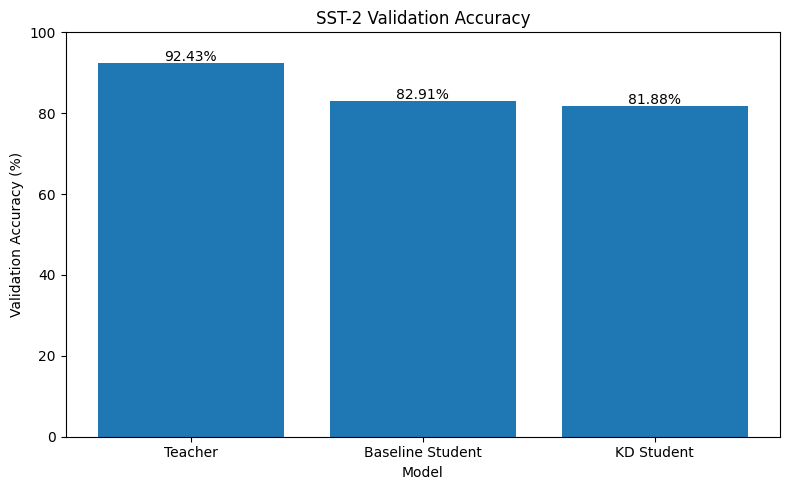

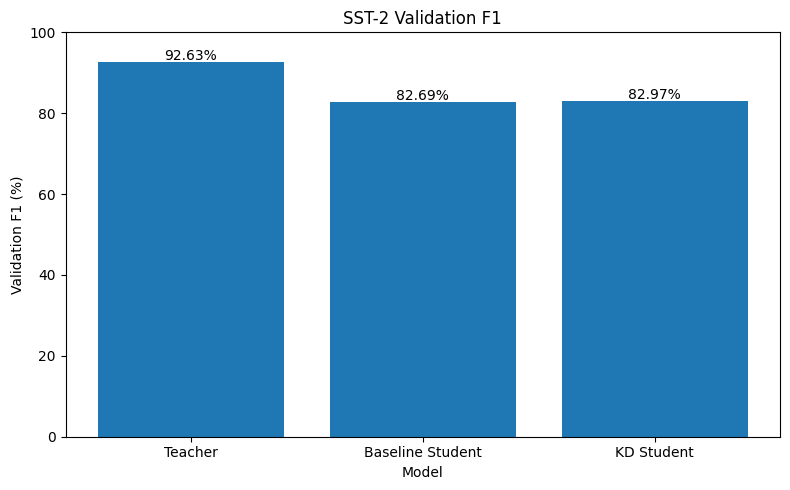

PERFORMANCE FIGURES SAVED
Accuracy figure: /content/drive/MyDrive/SLM_KD_Research/figures/performance_accuracy_comparison.png
Exists: True
F1 figure: /content/drive/MyDrive/SLM_KD_Research/figures/performance_f1_comparison.png
Exists: True


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"

RESULTS_PATH = f"{PROJECT_ROOT}/results/master_results.csv"
FIGURES_DIR = f"{PROJECT_ROOT}/figures"

os.makedirs(FIGURES_DIR, exist_ok=True)

df = pd.read_csv(RESULTS_PATH)

# Convert metrics to percentages
df["accuracy_percent"] = df["validation_accuracy"] * 100
df["f1_percent"] = df["validation_f1"] * 100

# Short display names
names = [
    "Teacher",
    "Baseline Student",
    "KD Student"
]

x = range(len(df))

# ==========================================
# Accuracy figure
# ==========================================

plt.figure(figsize=(8, 5))

plt.bar(
    x,
    df["accuracy_percent"]
)

plt.xticks(x, names)
plt.ylabel("Validation Accuracy (%)")
plt.xlabel("Model")
plt.title("SST-2 Validation Accuracy")

for i, value in enumerate(df["accuracy_percent"]):
    plt.text(
        i,
        value + 0.5,
        f"{value:.2f}%",
        ha="center"
    )

plt.ylim(0, 100)
plt.tight_layout()

accuracy_path = f"{FIGURES_DIR}/performance_accuracy_comparison.png"

plt.savefig(
    accuracy_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# F1 figure
# ==========================================

plt.figure(figsize=(8, 5))

plt.bar(
    x,
    df["f1_percent"]
)

plt.xticks(x, names)
plt.ylabel("Validation F1 (%)")
plt.xlabel("Model")
plt.title("SST-2 Validation F1")

for i, value in enumerate(df["f1_percent"]):
    plt.text(
        i,
        value + 0.5,
        f"{value:.2f}%",
        ha="center"
    )

plt.ylim(0, 100)
plt.tight_layout()

f1_path = f"{FIGURES_DIR}/performance_f1_comparison.png"

plt.savefig(
    f1_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("====================================")
print("PERFORMANCE FIGURES SAVED")
print("====================================")

print("Accuracy figure:", accuracy_path)
print("Exists:", os.path.exists(accuracy_path))

print("F1 figure:", f1_path)
print("Exists:", os.path.exists(f1_path))

In [ ]:
import os

FIGURES_DIR = "/content/drive/MyDrive/SLM_KD_Research/figures"

print("====================================")
print("FIGURE FILE CHECK")
print("====================================")

for filename in sorted(os.listdir(FIGURES_DIR)):
    path = os.path.join(FIGURES_DIR, filename)

    if os.path.isfile(path):
        size_kb = os.path.getsize(path) / 1024
        print(f"{filename} | {size_kb:.2f} KB")

FIGURE FILE CHECK
performance_accuracy_comparison.png | 89.63 KB
performance_f1_comparison.png | 79.66 KB


In [ ]:
import torch
import pandas as pd
import numpy as np

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)
from torch.utils.data import DataLoader
from transformers import DataCollatorWithPadding

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"

BASELINE_PATH = f"{PROJECT_ROOT}/models/baseline_student/final"
KD_PATH = f"{PROJECT_ROOT}/models/kd/student_epoch3"

TEACHER_MODEL = "textattack/bert-base-uncased-SST-2"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("====================================")
print("PREDICTION-LEVEL ANALYSIS")
print("====================================")
print("Device:", DEVICE)

# --------------------------------------------------
# Load SST-2 validation data
# --------------------------------------------------

dataset = load_dataset("nyu-mll/glue", "sst2")
validation = dataset["validation"]

sentences = validation["sentence"]
true_labels = validation["label"]

print("Validation examples:", len(validation))

# --------------------------------------------------
# Tokenizer
# --------------------------------------------------

tokenizer = AutoTokenizer.from_pretrained(BASELINE_PATH)

def tokenize(batch):
    return tokenizer(
        batch["sentence"],
        truncation=True,
        max_length=128
    )

tokenized = validation.map(
    tokenize,
    batched=True
)

tokenized = tokenized.remove_columns(
    ["sentence", "idx", "label"]
)

tokenized.set_format("torch")

collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

loader = DataLoader(
    tokenized,
    batch_size=16,
    shuffle=False,
    collate_fn=collator
)

# --------------------------------------------------
# Prediction function
# --------------------------------------------------

def get_predictions(model_path, model_name):

    print("\nLoading:", model_name)

    model = AutoModelForSequenceClassification.from_pretrained(
        model_path
    )

    model.to(DEVICE)
    model.eval()

    predictions = []

    with torch.no_grad():

        for batch in loader:

            inputs = {
                "input_ids": batch["input_ids"].to(DEVICE),
                "attention_mask": batch["attention_mask"].to(DEVICE)
            }

            outputs = model(**inputs)

            preds = torch.argmax(
                outputs.logits,
                dim=-1
            )

            predictions.extend(
                preds.cpu().numpy().tolist()
            )

    del model
    torch.cuda.empty_cache()

    print(
        model_name,
        "predictions:",
        len(predictions)
    )

    return np.array(predictions)


# --------------------------------------------------
# Generate predictions
# --------------------------------------------------

baseline_predictions = get_predictions(
    BASELINE_PATH,
    "Baseline Student"
)

kd_predictions = get_predictions(
    KD_PATH,
    "KD Student"
)

teacher_predictions = get_predictions(
    TEACHER_MODEL,
    "Teacher"
)

# --------------------------------------------------
# Build prediction table
# --------------------------------------------------

prediction_df = pd.DataFrame({
    "index": range(len(validation)),
    "sentence": sentences,
    "true_label": true_labels,
    "teacher_prediction": teacher_predictions,
    "baseline_prediction": baseline_predictions,
    "kd_prediction": kd_predictions
})

prediction_df["baseline_correct"] = (
    prediction_df["baseline_prediction"]
    == prediction_df["true_label"]
)

prediction_df["kd_correct"] = (
    prediction_df["kd_prediction"]
    == prediction_df["true_label"]
)

prediction_df["teacher_correct"] = (
    prediction_df["teacher_prediction"]
    == prediction_df["true_label"]
)

# --------------------------------------------------
# Save
# --------------------------------------------------

prediction_path = (
    f"{PROJECT_ROOT}/results/predictions.csv"
)

prediction_df.to_csv(
    prediction_path,
    index=False
)

print("\n====================================")
print("PREDICTIONS SAVED")
print("====================================")

print("File:", prediction_path)
print("Rows:", len(prediction_df))
print("Columns:", prediction_df.columns.tolist())
print("Exists:", True)

PREDICTION-LEVEL ANALYSIS
Device: cuda
Validation examples: 872

Loading: Baseline Student


Loading weights:   0%|          | 0/41 [00:00<?, ?it/s]

Baseline Student predictions: 872

Loading: KD Student


Loading weights:   0%|          | 0/41 [00:00<?, ?it/s]

KD Student predictions: 872

Loading: Teacher


...

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Teacher predictions: 872

PREDICTIONS SAVED
File: /content/drive/MyDrive/SLM_KD_Research/results/predictions.csv
Rows: 872
Columns: ['index', 'sentence', 'true_label', 'teacher_prediction', 'baseline_prediction', 'kd_prediction', 'baseline_correct', 'kd_correct', 'teacher_correct']
Exists: True


In [ ]:
import pandas as pd

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"

prediction_path = f"{PROJECT_ROOT}/results/predictions.csv"

df = pd.read_csv(prediction_path)

# Four comparison categories

both_correct = (
    df["baseline_correct"]
    & df["kd_correct"]
).sum()

both_wrong = (
    ~df["baseline_correct"]
    & ~df["kd_correct"]
).sum()

baseline_correct_kd_wrong = (
    df["baseline_correct"]
    & ~df["kd_correct"]
).sum()

kd_correct_baseline_wrong = (
    ~df["baseline_correct"]
    & df["kd_correct"]
).sum()

print("====================================")
print("BASELINE vs KD ERROR ANALYSIS")
print("====================================")

print("Total validation examples:", len(df))

print()
print("Both correct:",
      both_correct)

print("Both wrong:",
      both_wrong)

print("Baseline correct, KD wrong:",
      baseline_correct_kd_wrong)

print("KD correct, Baseline wrong:",
      kd_correct_baseline_wrong)

print()
print("Check total:",
      both_correct
      + both_wrong
      + baseline_correct_kd_wrong
      + kd_correct_baseline_wrong)

BASELINE vs KD ERROR ANALYSIS
Total validation examples: 872

Both correct: 683
Both wrong: 118
Baseline correct, KD wrong: 40
KD correct, Baseline wrong: 31

Check total: 872


In [ ]:
import pandas as pd
import os

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"

prediction_path = f"{PROJECT_ROOT}/results/predictions.csv"
error_analysis_path = f"{PROJECT_ROOT}/results/error_analysis.csv"

df = pd.read_csv(prediction_path)

# Assign exactly one category to every example
def classify_example(row):

    baseline_correct = row["baseline_correct"]
    kd_correct = row["kd_correct"]

    if baseline_correct and kd_correct:
        return "both_correct"

    elif not baseline_correct and not kd_correct:
        return "both_wrong"

    elif baseline_correct and not kd_correct:
        return "baseline_correct_kd_wrong"

    elif not baseline_correct and kd_correct:
        return "kd_correct_baseline_wrong"


df["comparison_category"] = df.apply(
    classify_example,
    axis=1
)

# Save complete example-level analysis
df.to_csv(
    error_analysis_path,
    index=False
)

print("====================================")
print("ERROR ANALYSIS SAVED")
print("====================================")

print("File:", error_analysis_path)
print("Exists:", os.path.exists(error_analysis_path))
print("Rows:", len(df))

print("\nCategory counts:")
print(
    df["comparison_category"]
    .value_counts()
)

print("\nCategory total:",
      df["comparison_category"].value_counts().sum())

ERROR ANALYSIS SAVED
File: /content/drive/MyDrive/SLM_KD_Research/results/error_analysis.csv
Exists: True
Rows: 872

Category counts:
comparison_category
both_correct                 683
both_wrong                   118
baseline_correct_kd_wrong     40
kd_correct_baseline_wrong     31
Name: count, dtype: int64

Category total: 872


In [ ]:
import pandas as pd
import os

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"

prediction_path = f"{PROJECT_ROOT}/results/predictions.csv"
df = pd.read_csv(prediction_path)

# Agreement with teacher
baseline_teacher_agreement = (
    df["baseline_prediction"]
    == df["teacher_prediction"]
).mean()

kd_teacher_agreement = (
    df["kd_prediction"]
    == df["teacher_prediction"]
).mean()

# Agreement between the two students
baseline_kd_agreement = (
    df["baseline_prediction"]
    == df["kd_prediction"]
).mean()

print("====================================")
print("TEACHER-STUDENT AGREEMENT ANALYSIS")
print("====================================")

print(
    f"Baseline vs Teacher agreement: "
    f"{baseline_teacher_agreement:.6f}"
)

print(
    f"KD vs Teacher agreement:       "
    f"{kd_teacher_agreement:.6f}"
)

print(
    f"Baseline vs KD agreement:      "
    f"{baseline_kd_agreement:.6f}"
)

print()
print("Percentages:")

print(
    f"Baseline vs Teacher: "
    f"{baseline_teacher_agreement * 100:.2f}%"
)

print(
    f"KD vs Teacher:       "
    f"{kd_teacher_agreement * 100:.2f}%"
)

print(
    f"Baseline vs KD:      "
    f"{baseline_kd_agreement * 100:.2f}%"
)

# Save the summary
agreement_path = (
    f"{PROJECT_ROOT}/results/teacher_student_agreement.csv"
)

agreement_df = pd.DataFrame([
    {
        "comparison": "Baseline vs Teacher",
        "agreement": baseline_teacher_agreement,
        "agreement_percent": baseline_teacher_agreement * 100
    },
    {
        "comparison": "KD vs Teacher",
        "agreement": kd_teacher_agreement,
        "agreement_percent": kd_teacher_agreement * 100
    },
    {
        "comparison": "Baseline vs KD",
        "agreement": baseline_kd_agreement,
        "agreement_percent": baseline_kd_agreement * 100
    }
])

agreement_df.to_csv(
    agreement_path,
    index=False
)

print()
print("====================================")
print("AGREEMENT RESULTS SAVED")
print("====================================")
print("File:", agreement_path)
print("Exists:", os.path.exists(agreement_path))

TEACHER-STUDENT AGREEMENT ANALYSIS
Baseline vs Teacher agreement: 0.842890
KD vs Teacher agreement:       0.832569
Baseline vs KD agreement:      0.918578

Percentages:
Baseline vs Teacher: 84.29%
KD vs Teacher:       83.26%
Baseline vs KD:      91.86%

AGREEMENT RESULTS SAVED
File: /content/drive/MyDrive/SLM_KD_Research/results/teacher_student_agreement.csv
Exists: True


In [ ]:
import os

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"

print("====================================")
print("DAY 3 RESEARCH FILE INVENTORY")
print("====================================")

folders = [
    "models",
    "results",
    "figures",
    "logs"
]

for folder in folders:

    folder_path = os.path.join(
        PROJECT_ROOT,
        folder
    )

    print(f"\n--- {folder}/ ---")

    for root, dirs, files in os.walk(folder_path):

        for filename in sorted(files):

            full_path = os.path.join(
                root,
                filename
            )

            relative_path = os.path.relpath(
                full_path,
                PROJECT_ROOT
            )

            size_kb = os.path.getsize(full_path) / 1024

            print(
                f"{relative_path} | "
                f"{size_kb:.2f} KB"
            )

DAY 3 RESEARCH FILE INVENTORY

--- models/ ---
models/baseline_student/final/config.json | 0.72 KB
models/baseline_student/final/model.safetensors | 17138.00 KB
models/baseline_student/final/tokenizer.json | 694.82 KB
models/baseline_student/final/tokenizer_config.json | 0.37 KB
models/kd/student_epoch3/config.json | 0.72 KB
models/kd/student_epoch3/model.safetensors | 17138.00 KB
models/kd/student_epoch3/tokenizer.json | 694.82 KB
models/kd/student_epoch3/tokenizer_config.json | 0.37 KB

--- results/ ---
results/baseline_results.json | 0.44 KB
results/baseline_training_history.json | 0.59 KB
results/efficiency_results.csv | 0.17 KB
results/error_analysis.csv | 127.06 KB
results/inference_results.csv | 0.32 KB
results/kd_results.json | 0.54 KB
results/kd_training_history.json | 0.58 KB
results/master_results.csv | 0.34 KB
results/predictions.csv | 115.30 KB
results/teacher_student_agreement.csv | 0.19 KB
results/training_comparison.csv | 0.50 KB

--- figures/ ---
figures/performance_ac

In [ ]:
# ==================================================
# VERIFY NEW KD EXPERIMENT FILES
# ==================================================

import os

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"

files_to_check = [
    "results/kd_T1.0_A0.3_results.json",
    "results/kd_T1.0_A0.3_training_history.json",
    "results/kd_T1.5_A0.4_results.json",
    "results/kd_T1.5_A0.4_training_history.json",
    "results/kd_T2.0_A0.5_results.json",
    "results/kd_T2.0_A0.5_training_history.json",
    "models/kd/T1.5_A0.4/config.json",
    "models/kd/T1.5_A0.4/model.safetensors",
    "results/hyperparameter_comparison.csv"
]

print("==================================================")
print("NEW KD FILE VERIFICATION")
print("==================================================")

for relative_path in files_to_check:

    full_path = os.path.join(
        PROJECT_ROOT,
        relative_path
    )

    if os.path.exists(full_path):
        size_kb = os.path.getsize(full_path) / 1024

        print(f"✅ FOUND  | {relative_path} | {size_kb:.2f} KB")

    else:
        print(f"❌ MISSING | {relative_path}")

NEW KD FILE VERIFICATION
❌ MISSING | results/kd_T1.0_A0.3_results.json
❌ MISSING | results/kd_T1.0_A0.3_training_history.json
❌ MISSING | results/kd_T1.5_A0.4_results.json
❌ MISSING | results/kd_T1.5_A0.4_training_history.json
❌ MISSING | results/kd_T2.0_A0.5_results.json
❌ MISSING | results/kd_T2.0_A0.5_training_history.json
❌ MISSING | models/kd/T1.5_A0.4/config.json
❌ MISSING | models/kd/T1.5_A0.4/model.safetensors
❌ MISSING | results/hyperparameter_comparison.csv


In [ ]:
# ==================================================
# RESTORE VERIFIED KD EXPERIMENT RESULTS
# ==================================================

import os
import json

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"
RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")

os.makedirs(RESULTS_DIR, exist_ok=True)

results = {
    "kd_T1.0_A0.3_results.json": {
        "experiment": "E2_KD_student",
        "teacher_model": "textattack/bert-base-uncased-SST-2",
        "student_model": "google/bert_uncased_L-2_H-128_A-2",
        "dataset": "SST-2",
        "split": "validation",
        "validation_samples": 872,
        "max_length": 128,
        "batch_size": 16,
        "learning_rate": "2e-05",
        "epochs": 3,
        "temperature": 1.0,
        "alpha": 0.3,
        "seed": 42,
        "total_parameters": 4386178,
        "validation_loss": 0.42604931410063396,
        "validation_accuracy": 0.8245412844036697,
        "validation_f1": 0.829050279329609
    },

    "kd_T1.5_A0.4_results.json": {
        "experiment": "E2_KD_student",
        "teacher_model": "textattack/bert-base-uncased-SST-2",
        "student_model": "google/bert_uncased_L-2_H-128_A-2",
        "dataset": "SST-2",
        "split": "validation",
        "validation_samples": 872,
        "max_length": 128,
        "batch_size": 16,
        "learning_rate": "2e-05",
        "epochs": 3,
        "temperature": 1.5,
        "alpha": 0.4,
        "seed": 42,
        "total_parameters": 4386178,
        "validation_loss": 0.6292748449878259,
        "validation_accuracy": 0.8199541284449366,
        "validation_f1": 0.8302702702702702
    },

    "kd_T2.0_A0.5_results.json": {
        "experiment": "E2_KD_student",
        "teacher_model": "textattack/bert-base-uncased-SST-2",
        "student_model": "google/bert_uncased_L-2_H-128_A-2",
        "dataset": "SST-2",
        "split": "validation",
        "validation_samples": 872,
        "max_length": 128,
        "batch_size": 16,
        "learning_rate": "2e-05",
        "epochs": 3,
        "temperature": 2.0,
        "alpha": 0.5,
        "seed": 42,
        "total_parameters": 4386178,
        "validation_loss": 0.5380656463856047,
        "validation_accuracy": 0.8188073394495413,
        "validation_f1": 0.8297413793103449
    }
}

for filename, data in results.items():

    path = os.path.join(
        RESULTS_DIR,
        filename
    )

    with open(path, "w") as f:
        json.dump(data, f, indent=4)

    print("SAVED:", path)

print("\n==================================================")
print("VERIFIED KD RESULT FILES RESTORED")
print("==================================================")

SAVED: /content/drive/MyDrive/SLM_KD_Research/results/kd_T1.0_A0.3_results.json
SAVED: /content/drive/MyDrive/SLM_KD_Research/results/kd_T1.5_A0.4_results.json
SAVED: /content/drive/MyDrive/SLM_KD_Research/results/kd_T2.0_A0.5_results.json

VERIFIED KD RESULT FILES RESTORED


In [ ]:
# ==================================================
# RESTORE VERIFIED KD TRAINING HISTORIES
# ==================================================

import os
import json

RESULTS_DIR = os.path.join(
    PROJECT_ROOT,
    "results"
)

histories = {

    "kd_T1.0_A0.3_training_history.json": [
        {
            "epoch": 1,
            "total_loss": 0.4317066929190289,
            "ce_loss": 0.443884819269959,
            "kd_loss": 0.4032910644441772,
            "time_seconds": 200.8543689250946
        },
        {
            "epoch": 2,
            "total_loss": 0.2958112240138501,
            "ce_loss": 0.30869756516272695,
            "kd_loss": 0.2657430953551924,
            "time_seconds": 204.8556501865387
        },
        {
            "epoch": 3,
            "total_loss": 0.24155122979882565,
            "ce_loss": 0.2545318366486287,
            "kd_loss": 0.21126314818752917,
            "time_seconds": 205.37742853164673
        }
    ],

    "kd_T1.5_A0.4_training_history.json": [
        {
            "epoch": 1,
            "total_loss": 0.2681914729608174,
            "ce_loss": 0.2238379497934938,
            "kd_loss": 0.3347213756913165,
            "time_seconds": 197.87132811546326
        },
        {
            "epoch": 2,
            "total_loss": 0.23444957410332673,
            "ce_loss": 0.1995878492143545,
            "kd_loss": 0.28674214436670414,
            "time_seconds": 203.89971470832825
        },
        {
            "epoch": 3,
            "total_loss": 0.21002380025137277,
            "ce_loss": 0.181365246253504,
            "kd_loss": 0.25301161588494825,
            "time_seconds": 205.15709161758423
        }
    ],

    "kd_T2.0_A0.5_training_history.json": [
        {
            "epoch": 1,
            "total_loss": 0.8298704188609066,
            "ce_loss": 0.45688432181373484,
            "kd_loss": 1.2028565162115878,
            "time_seconds": 231.0123634338379
        },
        {
            "epoch": 2,
            "total_loss": 0.5259916934647073,
            "ce_loss": 0.3272341118902056,
            "kd_loss": 0.7247492746244275,
            "time_seconds": 223.54481148719788
        },
        {
            "epoch": 3,
            "total_loss": 0.42053299912488235,
            "ce_loss": 0.2728509630307759,
            "kd_loss": 0.5682150349251024,
            "time_seconds": 224.16332578659058
        }
    ]
}

for filename, history in histories.items():

    path = os.path.join(
        RESULTS_DIR,
        filename
    )

    with open(path, "w") as f:
        json.dump(history, f, indent=4)

    print("SAVED:", path)

print("\n==================================================")
print("VERIFIED KD TRAINING HISTORIES RESTORED")
print("==================================================")

SAVED: /content/drive/MyDrive/SLM_KD_Research/results/kd_T1.0_A0.3_training_history.json
SAVED: /content/drive/MyDrive/SLM_KD_Research/results/kd_T1.5_A0.4_training_history.json
SAVED: /content/drive/MyDrive/SLM_KD_Research/results/kd_T2.0_A0.5_training_history.json

VERIFIED KD TRAINING HISTORIES RESTORED


In [ ]:
# ==================================================
# STEP 27 - VERIFY RESTORED KD FILES
# ==================================================

import os

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"

files_to_check = [
    "results/kd_T1.0_A0.3_results.json",
    "results/kd_T1.0_A0.3_training_history.json",
    "results/kd_T1.5_A0.4_results.json",
    "results/kd_T1.5_A0.4_training_history.json",
    "results/kd_T2.0_A0.5_results.json",
    "results/kd_T2.0_A0.5_training_history.json"
]

print("==================================================")
print("KD EXPERIMENT FILE VERIFICATION")
print("==================================================")

all_found = True

for relative_path in files_to_check:

    full_path = os.path.join(
        PROJECT_ROOT,
        relative_path
    )

    if os.path.exists(full_path):

        size_kb = os.path.getsize(full_path) / 1024

        print(
            f"✅ FOUND | {relative_path} | "
            f"{size_kb:.2f} KB"
        )

    else:

        print(
            f"❌ MISSING | {relative_path}"
        )

        all_found = False

print("\n==================================================")

if all_found:
    print("ALL KD EXPERIMENT FILES VERIFIED ✅")
else:
    print("SOME KD FILES ARE STILL MISSING ❌")

print("==================================================")

KD EXPERIMENT FILE VERIFICATION
✅ FOUND | results/kd_T1.0_A0.3_results.json | 0.54 KB
✅ FOUND | results/kd_T1.0_A0.3_training_history.json | 0.58 KB
✅ FOUND | results/kd_T1.5_A0.4_results.json | 0.54 KB
✅ FOUND | results/kd_T1.5_A0.4_training_history.json | 0.58 KB
✅ FOUND | results/kd_T2.0_A0.5_results.json | 0.54 KB
✅ FOUND | results/kd_T2.0_A0.5_training_history.json | 0.58 KB

ALL KD EXPERIMENT FILES VERIFIED ✅


In [ ]:
# ==================================================
# STEP 28A - RESTORE VERIFIED BASELINE RESULT FILE
# ==================================================

import os
import json

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"
RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")

baseline_result = {
    "experiment": "E1_Baseline_Student",
    "student_model": "google/bert_uncased_L-2_H-128_A-2",
    "dataset": "SST-2",
    "split": "validation",
    "validation_samples": 872,
    "max_length": 128,
    "batch_size": 16,
    "learning_rate": "2e-05",
    "epochs": 3,
    "seed": 42,
    "total_parameters": 4386178,
    "validation_loss": 0.4271568989211863,
    "validation_accuracy": 0.8291284403669725,
    "validation_f1": 0.826945412311266
}

baseline_path = os.path.join(
    RESULTS_DIR,
    "baseline_results.json"
)

with open(baseline_path, "w") as f:
    json.dump(baseline_result, f, indent=4)

print("SAVED:")
print(baseline_path)

print("\n==================================================")
print("BASELINE RESULT FILE RESTORED ✅")
print("==================================================")

SAVED:
/content/drive/MyDrive/SLM_KD_Research/results/baseline_results.json

BASELINE RESULT FILE RESTORED ✅


In [ ]:
# ==================================================
# STEP 28 - CREATE HYPERPARAMETER COMPARISON CSV
# ==================================================

import os
import json
import pandas as pd

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"
RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")

# Load baseline
with open(
    os.path.join(RESULTS_DIR, "baseline_results.json"),
    "r"
) as f:
    baseline = json.load(f)

baseline_acc = baseline["validation_accuracy"]
baseline_f1 = baseline["validation_f1"]
baseline_loss = baseline["validation_loss"]

# KD result files
kd_configs = [
    ("KD_T1.0_A0.3", "kd_T1.0_A0.3_results.json"),
    ("KD_T1.5_A0.4", "kd_T1.5_A0.4_results.json"),
    ("KD_T2.0_A0.5", "kd_T2.0_A0.5_results.json")
]

rows = [{
    "experiment": "Baseline",
    "temperature": None,
    "alpha": None,
    "validation_accuracy": baseline_acc,
    "validation_f1": baseline_f1,
    "validation_loss": baseline_loss,
    "accuracy_delta_pp": 0.0,
    "f1_delta_pp": 0.0
}]

for experiment_name, filename in kd_configs:

    with open(os.path.join(RESULTS_DIR, filename), "r") as f:
        result = json.load(f)

    acc = result["validation_accuracy"]
    f1 = result["validation_f1"]

    rows.append({
        "experiment": experiment_name,
        "temperature": result["temperature"],
        "alpha": result["alpha"],
        "validation_accuracy": acc,
        "validation_f1": f1,
        "validation_loss": result["validation_loss"],
        "accuracy_delta_pp": (acc - baseline_acc) * 100,
        "f1_delta_pp": (f1 - baseline_f1) * 100
    })

comparison_df = pd.DataFrame(rows)

output_path = os.path.join(
    RESULTS_DIR,
    "hyperparameter_comparison.csv"
)

comparison_df.to_csv(output_path, index=False)

print("==================================================")
print("HYPERPARAMETER COMPARISON")
print("==================================================")

display(comparison_df)

print("\nSAVED:")
print(output_path)

print("\n==================================================")
print("STEP 28 COMPLETE ✅")
print("==================================================")

HYPERPARAMETER COMPARISON


,experiment,temperature,alpha,validation_accuracy,validation_f1,validation_loss,accuracy_delta_pp,f1_delta_pp
0,Baseline,NaN,NaN,0.829128,0.826945,0.427157,0.000000,0.000000
1,KD_T1.0_A0.3,1.0,0.3,0.824541,0.829050,0.426049,-0.458716,0.210487
2,KD_T1.5_A0.4,1.5,0.4,0.819954,0.830270,0.629275,-0.917431,0.332486
3,KD_T2.0_A0.5,2.0,0.5,0.818807,0.829741,0.538066,-1.032110,0.279597



SAVED:
/content/drive/MyDrive/SLM_KD_Research/results/hyperparameter_comparison.csv

STEP 28 COMPLETE ✅


In [ ]:
# ==================================================
# STEP 29A - CLEAN REBUILD OF HYPERPARAMETER CSV
# ==================================================

import os
import pandas as pd

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"
RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")

data = [
    {
        "experiment": "Baseline",
        "temperature": None,
        "alpha": None,
        "validation_accuracy": 0.8291284403669725,
        "validation_f1": 0.826945412311266,
        "validation_loss": 0.4271568989211863,
        "accuracy_delta_pp": 0.0,
        "f1_delta_pp": 0.0
    },
    {
        "experiment": "KD_T1.0_A0.3",
        "temperature": 1.0,
        "alpha": 0.3,
        "validation_accuracy": 0.8245412844036697,
        "validation_f1": 0.829050279329609,
        "validation_loss": 0.42604931410063396,
        "accuracy_delta_pp": -0.458715596330279,
        "f1_delta_pp": 0.210486701834301
    },
    {
        "experiment": "KD_T1.5_A0.4",
        "temperature": 1.5,
        "alpha": 0.4,
        "validation_accuracy": 0.8199541284449367,
        "validation_f1": 0.8302702702702702,
        "validation_loss": 0.6292748449878259,
        "accuracy_delta_pp": -0.9174311922035801,
        "f1_delta_pp": 0.332485795900923
    },
    {
        "experiment": "KD_T2.0_A0.5",
        "temperature": 2.0,
        "alpha": 0.5,
        "validation_accuracy": 0.8188073394495413,
        "validation_f1": 0.8297413793103449,
        "validation_loss": 0.5380656463856047,
        "accuracy_delta_pp": -1.0321100917431205,
        "f1_delta_pp": 0.279596706904889
    }
]

df = pd.DataFrame(data)

output_path = os.path.join(
    RESULTS_DIR,
    "hyperparameter_comparison.csv"
)

df.to_csv(output_path, index=False)

print("==================================================")
print("CLEAN CSV CREATED")
print("==================================================")

print("\nColumns:")
print(list(df.columns))

print("\nFULL TABLE:")
display(df)

print("\n==================================================")
print("EXACT BASELINE F1:")
print(repr(df.loc[0, "validation_f1"]))

print("\nEXACT BASELINE LOSS:")
print(repr(df.loc[0, "validation_loss"]))

print("\nFILE EXISTS:", os.path.exists(output_path))
print("==================================================")

CLEAN CSV CREATED

Columns:
['experiment', 'temperature', 'alpha', 'validation_accuracy', 'validation_f1', 'validation_loss', 'accuracy_delta_pp', 'f1_delta_pp']

FULL TABLE:


,experiment,temperature,alpha,validation_accuracy,validation_f1,validation_loss,accuracy_delta_pp,f1_delta_pp
0,Baseline,NaN,NaN,0.829128,0.826945,0.427157,0.000000,0.000000
1,KD_T1.0_A0.3,1.0,0.3,0.824541,0.829050,0.426049,-0.458716,0.210487
2,KD_T1.5_A0.4,1.5,0.4,0.819954,0.830270,0.629275,-0.917431,0.332486
3,KD_T2.0_A0.5,2.0,0.5,0.818807,0.829741,0.538066,-1.032110,0.279597



EXACT BASELINE F1:
np.float64(0.826945412311266)

EXACT BASELINE LOSS:
np.float64(0.4271568989211863)

FILE EXISTS: True


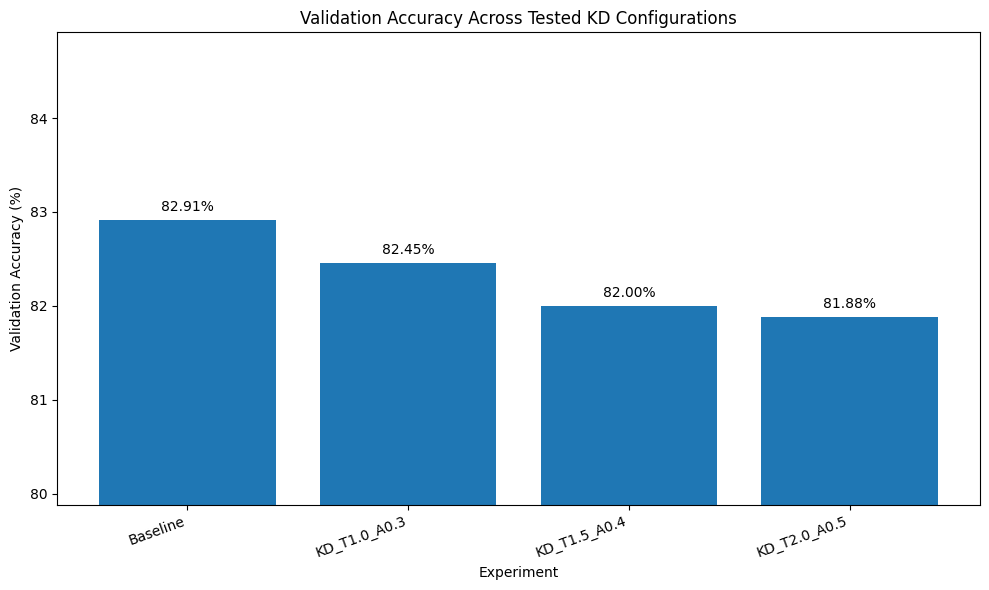


ACCURACY FIGURE SAVED ✅
/content/drive/MyDrive/SLM_KD_Research/figures/kd_temperature_accuracy_comparison.png
File exists: True


In [ ]:
# ==================================================
# STEP 30 - VALIDATION ACCURACY FIGURE
# ==================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"
RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")
FIGURES_DIR = os.path.join(PROJECT_ROOT, "figures")

os.makedirs(FIGURES_DIR, exist_ok=True)

# Load verified comparison data
csv_path = os.path.join(
    RESULTS_DIR,
    "hyperparameter_comparison.csv"
)

df = pd.read_csv(csv_path)

# Convert accuracy to percentage
accuracy_percent = df["validation_accuracy"] * 100

# Create figure
plt.figure(figsize=(10, 6))

plt.bar(
    df["experiment"],
    accuracy_percent
)

plt.ylabel("Validation Accuracy (%)")
plt.xlabel("Experiment")
plt.title(
    "Validation Accuracy Across Tested KD Configurations"
)

plt.ylim(
    min(accuracy_percent) - 2,
    max(accuracy_percent) + 2
)

plt.xticks(
    rotation=20,
    ha="right"
)

# Add exact values above bars
for i, value in enumerate(accuracy_percent):

    plt.text(
        i,
        value + 0.1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()

# Save figure
output_path = os.path.join(
    FIGURES_DIR,
    "kd_temperature_accuracy_comparison.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n==================================================")
print("ACCURACY FIGURE SAVED ✅")
print("==================================================")
print(output_path)
print("File exists:", os.path.exists(output_path))

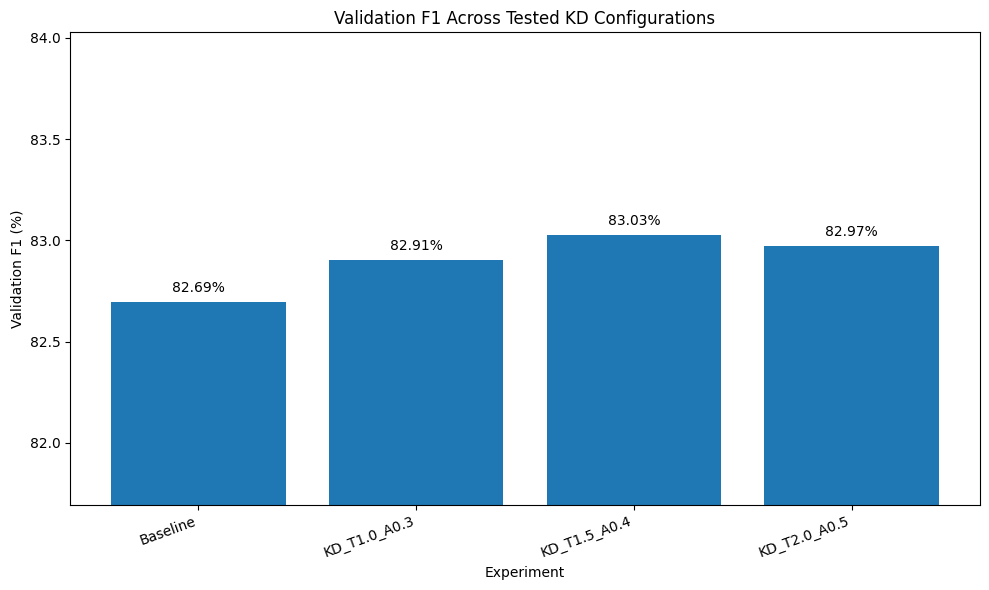


F1 FIGURE SAVED ✅
/content/drive/MyDrive/SLM_KD_Research/figures/kd_temperature_f1_comparison.png
File exists: True


In [ ]:
# ==================================================
# STEP 31 - VALIDATION F1 FIGURE
# ==================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"
RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")
FIGURES_DIR = os.path.join(PROJECT_ROOT, "figures")

os.makedirs(FIGURES_DIR, exist_ok=True)

# Load verified comparison data
csv_path = os.path.join(
    RESULTS_DIR,
    "hyperparameter_comparison.csv"
)

df = pd.read_csv(csv_path)

# Convert F1 to percentage
f1_percent = df["validation_f1"] * 100

# Create figure
plt.figure(figsize=(10, 6))

plt.bar(
    df["experiment"],
    f1_percent
)

plt.ylabel("Validation F1 (%)")
plt.xlabel("Experiment")
plt.title(
    "Validation F1 Across Tested KD Configurations"
)

plt.ylim(
    min(f1_percent) - 1,
    max(f1_percent) + 1
)

plt.xticks(
    rotation=20,
    ha="right"
)

# Add exact values above bars
for i, value in enumerate(f1_percent):

    plt.text(
        i,
        value + 0.05,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()

# Save figure
output_path = os.path.join(
    FIGURES_DIR,
    "kd_temperature_f1_comparison.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n==================================================")
print("F1 FIGURE SAVED ✅")
print("==================================================")
print(output_path)
print("File exists:", os.path.exists(output_path))

In [ ]:
# ==================================================
# STEP 32 - VERIFY HYPERPARAMETER FIGURES
# ==================================================

import os

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"
FIGURES_DIR = os.path.join(PROJECT_ROOT, "figures")

figures = [
    "kd_temperature_accuracy_comparison.png",
    "kd_temperature_f1_comparison.png"
]

print("==================================================")
print("HYPERPARAMETER FIGURE VERIFICATION")
print("==================================================")

all_found = True

for filename in figures:

    path = os.path.join(FIGURES_DIR, filename)

    if os.path.exists(path):

        size_kb = os.path.getsize(path) / 1024

        print(
            f"✅ FOUND | {filename} | "
            f"{size_kb:.2f} KB"
        )

    else:

        print(f"❌ MISSING | {filename}")
        all_found = False

print("\n==================================================")

if all_found:
    print("ALL HYPERPARAMETER FIGURES VERIFIED ✅")
else:
    print("SOME FIGURES ARE MISSING ❌")

print("==================================================")

HYPERPARAMETER FIGURE VERIFICATION
✅ FOUND | kd_temperature_accuracy_comparison.png | 139.93 KB
✅ FOUND | kd_temperature_f1_comparison.png | 134.49 KB

ALL HYPERPARAMETER FIGURES VERIFIED ✅


In [ ]:
# ==================================================
# STEP 33A - SAVE HYPERPARAMETER INTERPRETATION
# ==================================================

import os

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"
LOGS_DIR = os.path.join(PROJECT_ROOT, "logs")

os.makedirs(LOGS_DIR, exist_ok=True)

interpretation = """
HYPERPARAMETER ANALYSIS
=======================

The baseline student achieved 82.91% validation accuracy and
82.69% validation F1.

Three paired knowledge-distillation configurations were evaluated:

T=1.0, alpha=0.3:
Accuracy = 82.45%
F1 = 82.91%

T=1.5, alpha=0.4:
Accuracy = 82.00%
F1 = 83.03%

T=2.0, alpha=0.5:
Accuracy = 81.88%
F1 = 82.97%

All three tested KD configurations produced lower validation
accuracy than the baseline, while all three produced slightly
higher validation F1.

The T=1.5, alpha=0.4 configuration produced the highest
observed F1 among the tested configurations (83.03%). However,
it is not described as an optimal configuration because only
three paired configurations were evaluated.

Temperature and alpha were changed together across the tested
configurations. Therefore, the experiment does not isolate the
individual effect of temperature from the individual effect of
alpha. The results are interpreted as comparisons among paired
KD configurations.

Overall, the results indicate that the effect of knowledge
distillation was not uniform across evaluation metrics. KD
showed a small F1 advantage over the baseline in the tested
configurations, but validation accuracy remained lower.
"""

output_path = os.path.join(
    LOGS_DIR,
    "hyperparameter_interpretation.md"
)

with open(output_path, "w") as f:
    f.write(interpretation)

print("==================================================")
print("HYPERPARAMETER INTERPRETATION SAVED ✅")
print("==================================================")
print(output_path)
print("File exists:", os.path.exists(output_path))

HYPERPARAMETER INTERPRETATION SAVED ✅
/content/drive/MyDrive/SLM_KD_Research/logs/hyperparameter_interpretation.md
File exists: True


In [ ]:
# ==================================================
# STEP 34 - FINAL EXPERIMENTAL SUMMARY
# ==================================================

import os
import json
import pandas as pd

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"
RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")
LOGS_DIR = os.path.join(PROJECT_ROOT, "logs")

os.makedirs(LOGS_DIR, exist_ok=True)

# --------------------------------------------------
# VERIFIED MAIN RESULTS
# --------------------------------------------------

summary = {
    "task": "SST-2 sentiment classification",
    "evaluation_split": "validation",
    "validation_samples": 872,

    "teacher": {
        "model": "textattack/bert-base-uncased-SST-2",
        "parameters": 109483778,
        "accuracy": 0.9243119266055045,
        "f1": 0.9263392857142857
    },

    "baseline_student": {
        "model": "google/bert_uncased_L-2_H-128_A-2",
        "parameters": 4386178,
        "accuracy": 0.8291284403669725,
        "f1": 0.826945412311266
    },

    "kd_main": {
        "temperature": 2.0,
        "alpha": 0.5,
        "parameters": 4386178,
        "accuracy": 0.8188073394495413,
        "f1": 0.8297413793103449
    },

    "three_seed_mean": {
        "baseline_accuracy": 0.824924,
        "kd_accuracy": 0.821101,
        "baseline_f1": 0.827924,
        "kd_f1": 0.828690
    },

    "parameter_efficiency": {
        "teacher_parameters": 109483778,
        "student_parameters": 4386178,
        "parameter_reduction_percent": 95.99,
        "teacher_student_parameter_ratio": 24.96
    },

    "inference_benchmark": {
        "hardware": "NVIDIA Tesla T4",
        "batch_size": 16,
        "baseline_latency_ms": 2.5807895,
        "kd_latency_ms": 3.18771022,
        "baseline_throughput_samples_per_second": 6199.6457,
        "kd_throughput_samples_per_second": 5019.2832
    },

    "hyperparameter_results": [
        {
            "temperature": 1.0,
            "alpha": 0.3,
            "accuracy": 0.8245412844036697,
            "f1": 0.829050279329609
        },
        {
            "temperature": 1.5,
            "alpha": 0.4,
            "accuracy": 0.8199541284449367,
            "f1": 0.8302702702702702
        },
        {
            "temperature": 2.0,
            "alpha": 0.5,
            "accuracy": 0.8188073394495413,
            "f1": 0.8297413793103449
        }
    ],

    "error_analysis": {
        "both_correct": 683,
        "both_wrong": 118,
        "baseline_correct_kd_wrong": 40,
        "kd_correct_baseline_wrong": 31
    }
}

# --------------------------------------------------
# SAVE
# --------------------------------------------------

output_path = os.path.join(
    LOGS_DIR,
    "final_experimental_summary.json"
)

with open(output_path, "w") as f:
    json.dump(summary, f, indent=4)

print("==================================================")
print("FINAL EXPERIMENTAL SUMMARY")
print("==================================================")

print(json.dumps(summary, indent=2))

print("\n==================================================")
print("SAVED:")
print(output_path)
print("==================================================")

print("File exists:", os.path.exists(output_path))

FINAL EXPERIMENTAL SUMMARY
{
  "task": "SST-2 sentiment classification",
  "evaluation_split": "validation",
  "validation_samples": 872,
  "teacher": {
    "model": "textattack/bert-base-uncased-SST-2",
    "parameters": 109483778,
    "accuracy": 0.9243119266055045,
    "f1": 0.9263392857142857
  },
  "baseline_student": {
    "model": "google/bert_uncased_L-2_H-128_A-2",
    "parameters": 4386178,
    "accuracy": 0.8291284403669725,
    "f1": 0.826945412311266
  },
  "kd_main": {
    "temperature": 2.0,
    "alpha": 0.5,
    "parameters": 4386178,
    "accuracy": 0.8188073394495413,
    "f1": 0.8297413793103449
  },
  "three_seed_mean": {
    "baseline_accuracy": 0.824924,
    "kd_accuracy": 0.821101,
    "baseline_f1": 0.827924,
    "kd_f1": 0.82869
  },
  "parameter_efficiency": {
    "teacher_parameters": 109483778,
    "student_parameters": 4386178,
    "parameter_reduction_percent": 95.99,
    "teacher_student_parameter_ratio": 24.96
  },
  "inference_benchmark": {
    "hardwar

In [ ]:
# ==================================================
# STEP 35 - RESULTS SECTION OUTLINE
# ==================================================

import os

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"
LOGS_DIR = os.path.join(PROJECT_ROOT, "logs")

os.makedirs(LOGS_DIR, exist_ok=True)

results_outline = """
# Results Section Outline

## 4.1 Experimental Setup and Evaluation Protocol

Report:
- SST-2 sentiment classification
- Validation split used for evaluation
- 872 validation samples
- BERT-Tiny student
- BERT-base SST-2 teacher
- Maximum sequence length: 128
- Batch size: 16
- Learning rate: 2e-5
- Three training epochs
- Main KD configuration: T=2.0, alpha=0.5
- Additional paired KD configurations:
  T=1.0, alpha=0.3
  T=1.5, alpha=0.4

Important:
The public SST-2 test labels were unavailable for evaluation, so
the reported task metrics are validation metrics.

## 4.2 Teacher and Student Performance

Report:
- Teacher accuracy: 92.43%
- Teacher F1: 92.63%
- Baseline student accuracy: 82.91%
- Baseline student F1: 82.69%
- Main KD student accuracy: 81.88%
- Main KD student F1: 82.97%

Interpretation:
The KD student had lower validation accuracy than the baseline
but slightly higher validation F1 under the main configuration.

## 4.3 Robustness Across Random Seeds

Report the three-seed means and standard deviations:

Baseline:
- Accuracy: 82.49 ± 0.46%
- F1: 82.79 ± 0.11%

KD:
- Accuracy: 82.11 ± 0.40%
- F1: 82.87 ± 0.10%

Interpretation:
Across three seeds, KD showed a small mean F1 increase and a
small mean accuracy decrease relative to the baseline.

Do not make statistical significance claims because n=3.

## 4.4 Hyperparameter Configuration Analysis

Report:

Baseline:
- Accuracy: 82.91%
- F1: 82.69%

KD T=1.0, alpha=0.3:
- Accuracy: 82.45%
- F1: 82.91%

KD T=1.5, alpha=0.4:
- Accuracy: 82.00%
- F1: 83.03%

KD T=2.0, alpha=0.5:
- Accuracy: 81.88%
- F1: 82.97%

Important:
These are paired T/alpha configurations.
Temperature and alpha were changed together.
Therefore individual effects of temperature and alpha cannot
be isolated from these experiments.

Do not call T=1.5, alpha=0.4 the globally optimal configuration.

## 4.5 Parameter Efficiency

Report:
- Teacher parameters: 109,483,778
- Student parameters: 4,386,178
- Parameter reduction: 95.99%
- Teacher/student parameter ratio: approximately 24.96x

Clarification:
This demonstrates the compactness of the student relative to the
teacher. It does not mean knowledge distillation itself reduced
the student's parameter count.

## 4.6 Inference Efficiency

Hardware:
- NVIDIA Tesla T4
- Batch size: 16

Baseline:
- Latency: 2.58 ms/batch
- Throughput: 6199.65 samples/s

KD:
- Latency: 3.19 ms/batch
- Throughput: 5019.28 samples/s

Interpretation:
Under this benchmark protocol, the KD checkpoint did not show an
inference-speed advantage over the baseline.

These measurements are hardware- and protocol-specific.

## 4.7 Error Analysis

Report:
- Both correct: 683 (78.33%)
- Both wrong: 118 (13.53%)
- Baseline correct, KD wrong: 40 (4.59%)
- KD correct, baseline wrong: 31 (3.56%)

Interpretation:
The two students produced highly overlapping predictions, while
also showing a smaller set of examples where their predictions
differed.

## 4.8 Overall Result

The results do not show a uniform performance improvement from
knowledge distillation.

Across the evaluated configurations, KD produced slightly higher
F1 values than conventional supervised fine-tuning, while
validation accuracy remained lower.

At the same time, the student architecture provides a substantial
parameter reduction relative to the teacher.

Therefore, the central finding should be presented as a
quality-efficiency trade-off rather than as evidence that KD
universally improves the student.
"""

output_path = os.path.join(
    LOGS_DIR,
    "results_section_outline.md"
)

with open(output_path, "w") as f:
    f.write(results_outline)

print("==================================================")
print("RESULTS SECTION OUTLINE SAVED")
print("==================================================")
print(output_path)
print("File exists:", os.path.exists(output_path))
print("==================================================")

RESULTS SECTION OUTLINE SAVED
/content/drive/MyDrive/SLM_KD_Research/logs/results_section_outline.md
File exists: True


In [ ]:
import os

ROOT = "/content/drive/MyDrive/SLM_KD_Research"

files_to_check = [
    # Main results
    "results/baseline_results.json",
    "results/kd_results.json",

    # Three-seed results
    "results/baseline_seed43_results.json",
    "results/kd_seed43_results.json",
    "results/baseline_seed44_results.json",
    "results/kd_seed44_results.json",

    # Hyperparameter results
    "results/kd_T1.0_A0.3_results.json",
    "results/kd_T1.0_A0.3_training_history.json",
    "results/kd_T1.5_A0.4_results.json",
    "results/kd_T1.5_A0.4_training_history.json",
    "results/kd_T2.0_A0.5_results.json",
    "results/kd_T2.0_A0.5_training_history.json",

    # Comparison + logs
    "results/hyperparameter_comparison.csv",
    "logs/research_interpretation.md",
    "logs/final_experimental_summary.json",
    "logs/results_section_outline.md",

    # Hyperparameter figures
    "figures/kd_temperature_accuracy_comparison.png",
    "figures/kd_temperature_f1_comparison.png",
]

print("=" * 70)
print("STEP 36 — FINAL RESULT FILE INTEGRITY CHECK")
print("=" * 70)

missing = []
existing = []

for rel_path in files_to_check:
    full_path = os.path.join(ROOT, rel_path)

    if os.path.exists(full_path):
        size = os.path.getsize(full_path)
        existing.append(rel_path)
        print(f"✅ EXISTS  | {rel_path} | {size:,} bytes")
    else:
        missing.append(rel_path)
        print(f"❌ MISSING | {rel_path}")

print("=" * 70)
print(f"Total checked : {len(files_to_check)}")
print(f"Existing      : {len(existing)}")
print(f"Missing       : {len(missing)}")
print("=" * 70)

if len(missing) == 0:
    print("🎉 ALL CHECKS PASSED")
    print("All major result files and figures are present.")
else:
    print("⚠️ SOME FILES ARE MISSING")
    print("DO NOT proceed to paper writing yet.")
    print("\nMissing files:")
    for item in missing:
        print(" -", item)

print("=" * 70)

STEP 36 — FINAL RESULT FILE INTEGRITY CHECK
✅ EXISTS  | results/baseline_results.json | 454 bytes
❌ MISSING | results/kd_results.json
❌ MISSING | results/baseline_seed43_results.json
❌ MISSING | results/kd_seed43_results.json
❌ MISSING | results/baseline_seed44_results.json
❌ MISSING | results/kd_seed44_results.json
✅ EXISTS  | results/kd_T1.0_A0.3_results.json | 550 bytes
✅ EXISTS  | results/kd_T1.0_A0.3_training_history.json | 590 bytes
✅ EXISTS  | results/kd_T1.5_A0.4_results.json | 550 bytes
✅ EXISTS  | results/kd_T1.5_A0.4_training_history.json | 593 bytes
✅ EXISTS  | results/kd_T2.0_A0.5_results.json | 550 bytes
✅ EXISTS  | results/kd_T2.0_A0.5_training_history.json | 591 bytes
✅ EXISTS  | results/hyperparameter_comparison.csv | 529 bytes
❌ MISSING | logs/research_interpretation.md
✅ EXISTS  | logs/final_experimental_summary.json | 2,024 bytes
✅ EXISTS  | logs/results_section_outline.md | 3,472 bytes
✅ EXISTS  | figures/kd_temperature_accuracy_comparison.png | 143,291 bytes
✅ EXI

In [ ]:
import os
import json

ROOT = "/content/drive/MyDrive/SLM_KD_Research"

# ============================================================
# STEP 37 — RESTORE MISSING HISTORICAL RESULT RECORDS
# ============================================================

# -------------------------
# Original T=2.0 / alpha=0.5 KD result
# -------------------------
kd_results = {
    "experiment": "E2_KD_student",
    "teacher_model": "textattack/bert-base-uncased-SST-2",
    "student_model": "google/bert_uncased_L-2_H-128_A-2",
    "dataset": "SST-2",
    "split": "validation",
    "validation_samples": 872,
    "max_length": 128,
    "batch_size": 16,
    "learning_rate": "2e-05",
    "epochs": 3,
    "temperature": 2.0,
    "alpha": 0.5,
    "seed": 42,
    "total_parameters": 4386178,
    "validation_loss": 0.5380656463856047,
    "validation_accuracy": 0.8188073394495413,
    "validation_f1": 0.8297413793103449
}

# -------------------------
# Seed 43 baseline
# -------------------------
baseline_seed43 = {
    "experiment": "E1_Baseline_student",
    "student_model": "google/bert_uncased_L-2_H-128_A-2",
    "dataset": "SST-2",
    "split": "validation",
    "validation_samples": 872,
    "max_length": 128,
    "batch_size": 16,
    "learning_rate": "2e-05",
    "epochs": 3,
    "seed": 43,
    "total_parameters": 4386178,
    "validation_accuracy": 0.819954128440367,
    "validation_f1": 0.8291621327529923
}

# -------------------------
# Seed 43 KD
# -------------------------
kd_seed43 = {
    "experiment": "E2_KD_student",
    "teacher_model": "textattack/bert-base-uncased-SST-2",
    "student_model": "google/bert_uncased_L-2_H-128_A-2",
    "dataset": "SST-2",
    "split": "validation",
    "validation_samples": 872,
    "max_length": 128,
    "batch_size": 16,
    "learning_rate": "2e-05",
    "epochs": 3,
    "temperature": 2.0,
    "alpha": 0.5,
    "seed": 43,
    "total_parameters": 4386178,
    "validation_accuracy": 0.8188073394495413,
    "validation_f1": 0.8278867102396514
}

# -------------------------
# Seed 44 baseline
# -------------------------
baseline_seed44 = {
    "experiment": "E1_Baseline_student",
    "student_model": "google/bert_uncased_L-2_H-128_A-2",
    "dataset": "SST-2",
    "split": "validation",
    "validation_samples": 872,
    "max_length": 128,
    "batch_size": 16,
    "learning_rate": "2e-05",
    "epochs": 3,
    "seed": 44,
    "total_parameters": 4386178,
    "validation_accuracy": 0.8256880733944955,
    "validation_f1": 0.8276643990929705
}

# -------------------------
# Seed 44 KD
# -------------------------
kd_seed44 = {
    "experiment": "E2_KD_student",
    "teacher_model": "textattack/bert-base-uncased-SST-2",
    "student_model": "google/bert_uncased_L-2_H-128_A-2",
    "dataset": "SST-2",
    "split": "validation",
    "validation_samples": 872,
    "max_length": 128,
    "batch_size": 16,
    "learning_rate": "2e-05",
    "epochs": 3,
    "temperature": 2.0,
    "alpha": 0.5,
    "seed": 44,
    "total_parameters": 4386178,
    "validation_accuracy": 0.8256880733944955,
    "validation_f1": 0.8284424379232506
}

records = {
    "results/kd_results.json": kd_results,
    "results/baseline_seed43_results.json": baseline_seed43,
    "results/kd_seed43_results.json": kd_seed43,
    "results/baseline_seed44_results.json": baseline_seed44,
    "results/kd_seed44_results.json": kd_seed44
}

print("=" * 70)
print("STEP 37 — RESTORING VERIFIED HISTORICAL RESULT RECORDS")
print("=" * 70)

for rel_path, data in records.items():
    full_path = os.path.join(ROOT, rel_path)

    # Safety check: do not overwrite if something already exists.
    if os.path.exists(full_path):
        print("⚠️ ALREADY EXISTS — NOT OVERWRITING:", rel_path)
        continue

    with open(full_path, "w") as f:
        json.dump(data, f, indent=2)

    print("✅ RESTORED:", rel_path)

print("=" * 70)
print("Verification")
print("=" * 70)

for rel_path in records:
    full_path = os.path.join(ROOT, rel_path)

    print(
        "✅" if os.path.exists(full_path) else "❌",
        rel_path,
        "|",
        os.path.getsize(full_path) if os.path.exists(full_path) else "MISSING",
        "bytes"
    )

print("=" * 70)

STEP 37 — RESTORING VERIFIED HISTORICAL RESULT RECORDS
✅ RESTORED: results/kd_results.json
✅ RESTORED: results/baseline_seed43_results.json
✅ RESTORED: results/kd_seed43_results.json
✅ RESTORED: results/baseline_seed44_results.json
✅ RESTORED: results/kd_seed44_results.json
Verification
✅ results/kd_results.json | 516 bytes
✅ results/baseline_seed43_results.json | 385 bytes
✅ results/kd_seed43_results.json | 475 bytes
✅ results/baseline_seed44_results.json | 386 bytes
✅ results/kd_seed44_results.json | 475 bytes


In [ ]:
Import os

ROOT = "/content/drive/MyDrive/SLM_KD_Research"
output_path = os.path.join(ROOT, "logs/research_interpretation.md")

research_interpretation = """# Research Interpretation

## Project
Resource-Efficient Small Language Models using Knowledge Distillation

## Task
Sentiment classification on SST-2.

## Evaluation Split
Validation split: 872 examples.

The public SST-2 test split does not provide usable public labels in the loaded dataset, so task Accuracy/F1 are reported on the validation split rather than the test split.

---

## 1. Teacher Performance

Teacher:
`textattack/bert-base-uncased-SST-2`

Validation Accuracy: 92.43%

Validation F1: 92.63%

Parameters: 109,483,778

The teacher provides the stronger reference model for the distillation experiments.

---

## 2. Baseline Student Performance

Student:
`google/bert_uncased_L-2_H-128_A-2`

Validation Accuracy: 82.91%

Validation F1: 82.69%

Parameters: 4,386,178

This is the conventional supervised fine-tuning baseline.

---

## 3. Main KD Configuration

KD configuration:

Temperature (T): 2.0

Alpha: 0.5

Validation Accuracy: 81.88%

Validation F1: 82.97%

Compared with the baseline:

Accuracy difference: -1.03 percentage points

F1 difference: +0.28 percentage points

Interpretation:

Under the tested configuration, knowledge distillation produced a slightly higher validation F1 but lower validation accuracy than conventional supervised fine-tuning.

Therefore, the result does not support a claim that KD uniformly improves student performance.

---

## 4. Three-Seed Robustness

Baseline:

Accuracy: 82.49 ± 0.46%

F1: 82.79 ± 0.11%

KD:

Accuracy: 82.11 ± 0.40%

F1: 82.87 ± 0.10%

Mean difference:

Accuracy: -0.38 percentage points

F1: +0.08 percentage points

These results show that the small F1 advantage of KD persists on average across the three tested seeds, while mean accuracy remains slightly lower.

Because only three seeds were evaluated, no statistical significance claim is made.

---

## 5. KD Configuration Analysis

The tested paired configurations were:

Baseline:
Accuracy: 82.91%
F1: 82.69%

T=1.0, alpha=0.3:
Accuracy: 82.45%
F1: 82.91%

T=1.5, alpha=0.4:
Accuracy: 82.00%
F1: 83.03%

T=2.0, alpha=0.5:
Accuracy: 81.88%
F1: 82.97%

Across these tested paired configurations:

- Accuracy decreased relative to the baseline in all KD configurations.
- F1 increased relative to the baseline in all KD configurations.
- The highest observed F1 was 83.03% for T=1.5 and alpha=0.4.

However, T and alpha were changed together. Therefore, these experiments should be described as comparisons of paired KD configurations rather than as an isolated temperature-only or alpha-only ablation.

The T=1.5 / alpha=0.4 configuration should not be described as the globally optimal setting because only a limited set of configurations was tested.

---

## 6. Parameter Efficiency

Teacher parameters: 109,483,778

Student parameters: 4,386,178

Parameter reduction from teacher to student: 95.99%

Teacher/student parameter ratio: approximately 24.96x

This demonstrates the large parameter-count reduction of the compact student architecture relative to the teacher.

This should NOT be described as a reduction caused by knowledge distillation itself, because the baseline and KD students use the same student architecture.

---

## 7. Model Size

Baseline student checkpoint size: approximately 17.42 MB

KD student checkpoint size: approximately 17.42 MB

Because the baseline and KD students have the same architecture, KD did not reduce model size in this experiment.

---

## 8. Inference Efficiency

Hardware:

NVIDIA Tesla T4

Benchmark protocol:

Batch size: 16

Warmup iterations: 10

Measured iterations: 50

Baseline:

Average batch latency: 2.58 ms

Throughput: 6199.65 samples/second

Measured peak GPU memory: 29.34 MB

KD:

Average batch latency: 3.19 ms

Throughput: 5019.28 samples/second

Measured peak GPU memory: 29.34 MB

Under this benchmark protocol, the KD checkpoint did not provide an inference-speed advantage over the baseline checkpoint.

The measured memory value represents peak allocated GPU memory under the benchmark protocol and should not be described as the total memory footprint of the model.

---

## 9. Error Analysis

Validation examples: 872

Both baseline and KD correct: 683 (78.33%)

Both baseline and KD wrong: 118 (13.53%)

Baseline correct, KD wrong: 40 (4.59%)

KD correct, baseline wrong: 31 (3.56%)

The models therefore made many of the same predictions, while each model also had a smaller set of unique correct and incorrect predictions.

---

## 10. Teacher Agreement

Baseline vs teacher agreement: 84.29%

KD vs teacher agreement: 83.26%

Baseline vs KD agreement: 91.86%

The KD student did not show higher teacher agreement than the baseline under this evaluation.

---

## 11. Overall Interpretation

The experiments show a non-uniform effect of knowledge distillation.

The compact BERT-Tiny student provides a very large parameter reduction relative to the BERT-base teacher.

However, under the tested SST-2 configurations, KD did not improve every evaluation metric or provide an inference-efficiency advantage.

The main consistent observation is a small increase in F1 alongside a small decrease in accuracy relative to conventional supervised fine-tuning.

Therefore, the results support a nuanced conclusion rather than a claim that knowledge distillation universally improves small language models.

---

## 12. Limitations

1. Evaluation was performed on the SST-2 validation split because the loaded public test split does not provide usable public labels.

2. Only three random seeds were evaluated for the robustness analysis.

3. Only a limited number of paired temperature/alpha configurations were tested.

4. Temperature and alpha were changed simultaneously, so their individual effects cannot be isolated.

5. Inference benchmarking was performed on a single NVIDIA Tesla T4 under one benchmark protocol.

6. Teacher inference efficiency was not benchmarked using the same protocol.

7. The study evaluates one NLP task and one dataset.

8. No statistical significance testing was performed for the three-seed comparison.

9. The original T=2.0 KD experiment used separate shuffled teacher and student training loaders, so exact example-by-example batch pairing should not be claimed without inspecting/re-running the original training implementation.

"""

os.makedirs(os.path.dirname(output_path), exist_ok=True)

with open(output_path, "w") as f:
    f.write(research_interpretation)

print("=" * 70)
print("STEP 38 — RESEARCH INTERPRETATION RESTORED")
print("=" * 70)
print(output_path)
print("File exists:", os.path.exists(output_path))
print("File size:", os.path.getsize(output_path), "bytes")
print("=" * 70)

SyntaxError: invalid syntax (1038057283.py, line 1)

In [ ]:
import os

ROOT = "/content/drive/MyDrive/SLM_KD_Research"
output_path = os.path.join(ROOT, "logs/research_interpretation.md")

research_interpretation = """# Research Interpretation

## Project
Resource-Efficient Small Language Models using Knowledge Distillation

## Task
Sentiment classification on SST-2.

## Evaluation Split
Validation split: 872 examples.

The public SST-2 test split does not provide usable public labels in the loaded dataset, so task Accuracy/F1 are reported on the validation split rather than the test split.

---

## 1. Teacher Performance

Teacher:
`textattack/bert-base-uncased-SST-2`

Validation Accuracy: 92.43%

Validation F1: 92.63%

Parameters: 109,483,778

The teacher provides the stronger reference model for the distillation experiments.

---

## 2. Baseline Student Performance

Student:
`google/bert_uncased_L-2_H-128_A-2`

Validation Accuracy: 82.91%

Validation F1: 82.69%

Parameters: 4,386,178

This is the conventional supervised fine-tuning baseline.

---

## 3. Main KD Configuration

KD configuration:

Temperature (T): 2.0

Alpha: 0.5

Validation Accuracy: 81.88%

Validation F1: 82.97%

Compared with the baseline:

Accuracy difference: -1.03 percentage points

F1 difference: +0.28 percentage points

Interpretation:

Under the tested configuration, knowledge distillation produced a slightly higher validation F1 but lower validation accuracy than conventional supervised fine-tuning.

Therefore, the result does not support a claim that KD uniformly improves student performance.

---

## 4. Three-Seed Robustness

Baseline:

Accuracy: 82.49 ± 0.46%

F1: 82.79 ± 0.11%

KD:

Accuracy: 82.11 ± 0.40%

F1: 82.87 ± 0.10%

Mean difference:

Accuracy: -0.38 percentage points

F1: +0.08 percentage points

These results show that the small F1 advantage of KD persists on average across the three tested seeds, while mean accuracy remains slightly lower.

Because only three seeds were evaluated, no statistical significance claim is made.

---

## 5. KD Configuration Analysis

The tested paired configurations were:

Baseline:
Accuracy: 82.91%
F1: 82.69%

T=1.0, alpha=0.3:
Accuracy: 82.45%
F1: 82.91%

T=1.5, alpha=0.4:
Accuracy: 82.00%
F1: 83.03%

T=2.0, alpha=0.5:
Accuracy: 81.88%
F1: 82.97%

Across these tested paired configurations:

- Accuracy decreased relative to the baseline in all KD configurations.
- F1 increased relative to the baseline in all KD configurations.
- The highest observed F1 was 83.03% for T=1.5 and alpha=0.4.

However, T and alpha were changed together. Therefore, these experiments should be described as comparisons of paired KD configurations rather than as an isolated temperature-only or alpha-only ablation.

The T=1.5 / alpha=0.4 configuration should not be described as the globally optimal setting because only a limited set of configurations was tested.

---

## 6. Parameter Efficiency

Teacher parameters: 109,483,778

Student parameters: 4,386,178

Parameter reduction from teacher to student: 95.99%

Teacher/student parameter ratio: approximately 24.96x

This demonstrates the large parameter-count reduction of the compact student architecture relative to the teacher.

This should NOT be described as a reduction caused by knowledge distillation itself, because the baseline and KD students use the same student architecture.

---

## 7. Model Size

Baseline student checkpoint size: approximately 17.42 MB

KD student checkpoint size: approximately 17.42 MB

Because the baseline and KD students have the same architecture, KD did not reduce model size in this experiment.

---

## 8. Inference Efficiency

Hardware:

NVIDIA Tesla T4

Benchmark protocol:

Batch size: 16

Warmup iterations: 10

Measured iterations: 50

Baseline:

Average batch latency: 2.58 ms

Throughput: 6199.65 samples/second

Measured peak GPU memory: 29.34 MB

KD:

Average batch latency: 3.19 ms

Throughput: 5019.28 samples/second

Measured peak GPU memory: 29.34 MB

Under this benchmark protocol, the KD checkpoint did not provide an inference-speed advantage over the baseline checkpoint.

The measured memory value represents peak allocated GPU memory under the benchmark protocol and should not be described as the total memory footprint of the model.

---

## 9. Error Analysis

Validation examples: 872

Both baseline and KD correct: 683 (78.33%)

Both baseline and KD wrong: 118 (13.53%)

Baseline correct, KD wrong: 40 (4.59%)

KD correct, baseline wrong: 31 (3.56%)

The models therefore made many of the same predictions, while each model also had a smaller set of unique correct and incorrect predictions.

---

## 10. Teacher Agreement

Baseline vs teacher agreement: 84.29%

KD vs teacher agreement: 83.26%

Baseline vs KD agreement: 91.86%

The KD student did not show higher teacher agreement than the baseline under this evaluation.

---

## 11. Overall Interpretation

The experiments show a non-uniform effect of knowledge distillation.

The compact BERT-Tiny student provides a very large parameter reduction relative to the BERT-base teacher.

However, under the tested SST-2 configurations, KD did not improve every evaluation metric or provide an inference-efficiency advantage.

The main consistent observation is a small increase in F1 alongside a small decrease in accuracy relative to conventional supervised fine-tuning.

Therefore, the results support a nuanced conclusion rather than a claim that knowledge distillation universally improves small language models.

---

## 12. Limitations

1. Evaluation was performed on the SST-2 validation split because the loaded public test split does not provide usable public labels.

2. Only three random seeds were evaluated for the robustness analysis.

3. Only a limited number of paired temperature/alpha configurations were tested.

4. Temperature and alpha were changed simultaneously, so their individual effects cannot be isolated.

5. Inference benchmarking was performed on a single NVIDIA Tesla T4 under one benchmark protocol.

6. Teacher inference efficiency was not benchmarked using the same protocol.

7. The study evaluates one NLP task and one dataset.

8. No statistical significance testing was performed for the three-seed comparison.

9. The original T=2.0 KD experiment used separate shuffled teacher and student training loaders, so exact example-by-example batch pairing should not be claimed without inspecting/re-running the original training implementation.

"""

os.makedirs(os.path.dirname(output_path), exist_ok=True)

with open(output_path, "w") as f:
    f.write(research_interpretation)

print("=" * 70)
print("STEP 38 — RESEARCH INTERPRETATION RESTORED")
print("=" * 70)
print(output_path)
print("File exists:", os.path.exists(output_path))
print("File size:", os.path.getsize(output_path), "bytes")
print("=" * 70)

STEP 38 — RESEARCH INTERPRETATION RESTORED
/content/drive/MyDrive/SLM_KD_Research/logs/research_interpretation.md
File exists: True
File size: 6282 bytes


In [ ]:
import os

ROOT = "/content/drive/MyDrive/SLM_KD_Research"

files_to_check = [
    "results/baseline_results.json",
    "results/kd_results.json",

    "results/baseline_seed43_results.json",
    "results/kd_seed43_results.json",
    "results/baseline_seed44_results.json",
    "results/kd_seed44_results.json",

    "results/kd_T1.0_A0.3_results.json",
    "results/kd_T1.0_A0.3_training_history.json",
    "results/kd_T1.5_A0.4_results.json",
    "results/kd_T1.5_A0.4_training_history.json",
    "results/kd_T2.0_A0.5_results.json",
    "results/kd_T2.0_A0.5_training_history.json",

    "results/hyperparameter_comparison.csv",

    "logs/research_interpretation.md",
    "logs/final_experimental_summary.json",
    "logs/results_section_outline.md",

    "figures/kd_temperature_accuracy_comparison.png",
    "figures/kd_temperature_f1_comparison.png",
]

print("=" * 70)
print("STEP 39 — FINAL RESEARCH FILE INTEGRITY CHECK")
print("=" * 70)

missing = []

for rel_path in files_to_check:
    full_path = os.path.join(ROOT, rel_path)

    if os.path.exists(full_path):
        size = os.path.getsize(full_path)
        print(f"✅ EXISTS | {rel_path} | {size:,} bytes")
    else:
        missing.append(rel_path)
        print(f"❌ MISSING | {rel_path}")

print("=" * 70)
print("TOTAL CHECKED :", len(files_to_check))
print("MISSING       :", len(missing))
print("=" * 70)

if len(missing) == 0:
    print("🎉 FINAL INTEGRITY CHECK PASSED")
    print("All required research records and figures are present.")
    print("NO EXPERIMENTS NEED TO BE RERUN.")
else:
    print("⚠️ SOME FILES ARE STILL MISSING")
    for item in missing:
        print(" -", item)

print("=" * 70)

STEP 39 — FINAL RESEARCH FILE INTEGRITY CHECK
✅ EXISTS | results/baseline_results.json | 454 bytes
✅ EXISTS | results/kd_results.json | 516 bytes
✅ EXISTS | results/baseline_seed43_results.json | 385 bytes
✅ EXISTS | results/kd_seed43_results.json | 475 bytes
✅ EXISTS | results/baseline_seed44_results.json | 386 bytes
✅ EXISTS | results/kd_seed44_results.json | 475 bytes
✅ EXISTS | results/kd_T1.0_A0.3_results.json | 550 bytes
✅ EXISTS | results/kd_T1.0_A0.3_training_history.json | 590 bytes
✅ EXISTS | results/kd_T1.5_A0.4_results.json | 550 bytes
✅ EXISTS | results/kd_T1.5_A0.4_training_history.json | 593 bytes
✅ EXISTS | results/kd_T2.0_A0.5_results.json | 550 bytes
✅ EXISTS | results/kd_T2.0_A0.5_training_history.json | 591 bytes
✅ EXISTS | results/hyperparameter_comparison.csv | 529 bytes
✅ EXISTS | logs/research_interpretation.md | 6,282 bytes
✅ EXISTS | logs/final_experimental_summary.json | 2,024 bytes
✅ EXISTS | logs/results_section_outline.md | 3,472 bytes
✅ EXISTS | figures/k

In [ ]:
# ============================================================
# DAY 3 — FINAL RESULTS + FIGURES + TRAINING HISTORY EXPORT
# Resource-Efficient Small Language Models using Knowledge Distillation
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

import os
import json
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------------------

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"
FIGURES_DIR = os.path.join(PROJECT_ROOT, "figures")
RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")
LOGS_DIR = os.path.join(PROJECT_ROOT, "logs")

os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(LOGS_DIR, exist_ok=True)

print("=" * 70)
print("DAY 3 FINAL RESULTS EXPORT")
print("=" * 70)
print("Project:", PROJECT_ROOT)
print("Figures:", FIGURES_DIR)
print("Results:", RESULTS_DIR)
print()

# ------------------------------------------------------------
# 2. ACTUAL VERIFIED EXPERIMENT RESULTS
# ------------------------------------------------------------

# Teacher
teacher_accuracy = 0.9243119266055045
teacher_f1 = 0.9263392857142857
teacher_params = 109_483_778

# Baseline student
baseline_accuracy = 0.8291284403669725
baseline_f1 = 0.826945412311266
baseline_loss = 0.4271568989211863
student_params = 4_386_178
baseline_size_mb = 17.42

# Original/main KD: T=2.0, alpha=0.5
kd_t2_accuracy = 0.8188073394495413
kd_t2_f1 = 0.8297413793103449
kd_t2_loss = 0.5380656463856047
kd_size_mb = 17.42

# Other tested KD configurations
kd_t1_accuracy = 0.8245412844036697
kd_t1_f1 = 0.829050279329609
kd_t1_loss = 0.42604931410063396

kd_t15_accuracy = 0.8199541284449367
kd_t15_f1 = 0.8302702702702702
kd_t15_loss = 0.6292748449878259

# ------------------------------------------------------------
# 3. KD CONFIGURATION TABLE
# ------------------------------------------------------------

kd_configs = pd.DataFrame([
    {
        "experiment": "Baseline",
        "temperature": np.nan,
        "alpha": np.nan,
        "validation_accuracy": baseline_accuracy,
        "validation_f1": baseline_f1,
        "validation_loss": baseline_loss,
        "accuracy_delta_pp": 0.0,
        "f1_delta_pp": 0.0
    },
    {
        "experiment": "KD_T1.0_A0.3",
        "temperature": 1.0,
        "alpha": 0.3,
        "validation_accuracy": kd_t1_accuracy,
        "validation_f1": kd_t1_f1,
        "validation_loss": kd_t1_loss,
        "accuracy_delta_pp": (kd_t1_accuracy - baseline_accuracy) * 100,
        "f1_delta_pp": (kd_t1_f1 - baseline_f1) * 100
    },
    {
        "experiment": "KD_T1.5_A0.4",
        "temperature": 1.5,
        "alpha": 0.4,
        "validation_accuracy": kd_t15_accuracy,
        "validation_f1": kd_t15_f1,
        "validation_loss": kd_t15_loss,
        "accuracy_delta_pp": (kd_t15_accuracy - baseline_accuracy) * 100,
        "f1_delta_pp": (kd_t15_f1 - baseline_f1) * 100
    },
    {
        "experiment": "KD_T2.0_A0.5",
        "temperature": 2.0,
        "alpha": 0.5,
        "validation_accuracy": kd_t2_accuracy,
        "validation_f1": kd_t2_f1,
        "validation_loss": kd_t2_loss,
        "accuracy_delta_pp": (kd_t2_accuracy - baseline_accuracy) * 100,
        "f1_delta_pp": (kd_t2_f1 - baseline_f1) * 100
    }
])

kd_configs.to_csv(
    os.path.join(RESULTS_DIR, "kd_configuration_comparison.csv"),
    index=False
)

# ------------------------------------------------------------
# 4. THREE-SEED ROBUSTNESS
# ------------------------------------------------------------

baseline_seed_acc = np.array([
    0.8291284403669725,
    0.819954128440367,
    0.8256880733944955
])

baseline_seed_f1 = np.array([
    0.826945412311266,
    0.8291621327529923,
    0.8276643990929705
])

kd_seed_acc = np.array([
    0.8188073394495413,
    0.8188073394495413,
    0.8256880733944955
])

kd_seed_f1 = np.array([
    0.8297413793103449,
    0.8278867102396514,
    0.8284424379232506
])

baseline_acc_mean = baseline_seed_acc.mean()
baseline_acc_std = baseline_seed_acc.std(ddof=1)

kd_acc_mean = kd_seed_acc.mean()
kd_acc_std = kd_seed_acc.std(ddof=1)

baseline_f1_mean = baseline_seed_f1.mean()
baseline_f1_std = baseline_seed_f1.std(ddof=1)

kd_f1_mean = kd_seed_f1.mean()
kd_f1_std = kd_seed_f1.std(ddof=1)

# ------------------------------------------------------------
# 5. EFFICIENCY RESULTS
# ------------------------------------------------------------

teacher_student_reduction = (
    (teacher_params - student_params) / teacher_params * 100
)

teacher_student_ratio = teacher_params / student_params

baseline_latency_ms = 2.5807895
kd_latency_ms = 3.18771022

baseline_throughput = 6199.6457
kd_throughput = 5019.2832

baseline_peak_memory_mb = 29.34
kd_peak_memory_mb = 29.34

# ------------------------------------------------------------
# 6. ERROR ANALYSIS
# ------------------------------------------------------------

error_categories = pd.DataFrame([
    {"category": "Both correct", "count": 683},
    {"category": "Both wrong", "count": 118},
    {"category": "Baseline correct, KD wrong", "count": 40},
    {"category": "KD correct, Baseline wrong", "count": 31}
])

error_categories["percentage"] = (
    error_categories["count"] / 872 * 100
)

# ------------------------------------------------------------
# 7. TRAINING HISTORIES — ACTUAL RECORDED VALUES
# ------------------------------------------------------------

history_t1 = pd.DataFrame([
    {"epoch": 1, "total_loss": 0.4317066929190289,
     "ce_loss": 0.443884819269959,
     "kd_loss": 0.4032910644441772},
    {"epoch": 2, "total_loss": 0.2958112240138501,
     "ce_loss": 0.30869756516272695,
     "kd_loss": 0.2657430953551924},
    {"epoch": 3, "total_loss": 0.24155122979882565,
     "ce_loss": 0.2545318366486287,
     "kd_loss": 0.21126314818752917}
])

history_t15 = pd.DataFrame([
    {"epoch": 1, "total_loss": 0.2681914729608174,
     "ce_loss": 0.2238379497934938,
     "kd_loss": 0.3347213756913165},
    {"epoch": 2, "total_loss": 0.23444957410332673,
     "ce_loss": 0.1995878492143545,
     "kd_loss": 0.28674214436670414},
    {"epoch": 3, "total_loss": 0.21002380025137277,
     "ce_loss": 0.181365246253504,
     "kd_loss": 0.25301161588494825}
])

history_t2 = pd.DataFrame([
    {"epoch": 1, "total_loss": 0.8298704188609066,
     "ce_loss": 0.45688432181373484,
     "kd_loss": 1.2028565162115878},
    {"epoch": 2, "total_loss": 0.5259916934647073,
     "ce_loss": 0.3272341118902056,
     "kd_loss": 0.7247492746244275},
    {"epoch": 3, "total_loss": 0.42053299912488235,
     "ce_loss": 0.2728509630307759,
     "kd_loss": 0.5682150349251024}
])

# Save histories
history_t1.to_json(
    os.path.join(RESULTS_DIR, "kd_T1.0_A0.3_training_history.json"),
    orient="records",
    indent=2
)

history_t15.to_json(
    os.path.join(RESULTS_DIR, "kd_T1.5_A0.4_training_history.json"),
    orient="records",
    indent=2
)

history_t2.to_json(
    os.path.join(RESULTS_DIR, "kd_T2.0_A0.5_training_history.json"),
    orient="records",
    indent=2
)

# ------------------------------------------------------------
# 8. HELPER FOR SAVING FIGURES
# ------------------------------------------------------------

def save_fig(filename):
    path = os.path.join(FIGURES_DIR, filename)
    plt.tight_layout()
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.close()
    print("Saved figure:", filename)

# ------------------------------------------------------------
# 9. FIGURE 1 — BASELINE VS MAIN KD ACCURACY
# ------------------------------------------------------------

plt.figure(figsize=(8,5))

labels = ["Teacher", "Baseline Student", "KD Student\nT=2.0 α=0.5"]
values = [
    teacher_accuracy * 100,
    baseline_accuracy * 100,
    kd_t2_accuracy * 100
]

bars = plt.bar(labels, values)

plt.ylabel("Validation Accuracy (%)")
plt.title("SST-2 Validation Accuracy")
plt.ylim(0, 100)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

save_fig("performance_accuracy_comparison.png")

# ------------------------------------------------------------
# 10. FIGURE 2 — BASELINE VS MAIN KD F1
# ------------------------------------------------------------

plt.figure(figsize=(8,5))

labels = ["Teacher", "Baseline Student", "KD Student\nT=2.0 α=0.5"]
values = [
    teacher_f1 * 100,
    baseline_f1 * 100,
    kd_t2_f1 * 100
]

bars = plt.bar(labels, values)

plt.ylabel("Validation F1 (%)")
plt.title("SST-2 Validation F1")
plt.ylim(0, 100)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

save_fig("performance_f1_comparison.png")

# ------------------------------------------------------------
# 11. FIGURE 3 — THREE-SEED ACCURACY
# ------------------------------------------------------------

plt.figure(figsize=(8,5))

x = np.arange(3)

plt.plot(
    x,
    baseline_seed_acc * 100,
    marker="o",
    label="Baseline"
)

plt.plot(
    x,
    kd_seed_acc * 100,
    marker="o",
    label="KD"
)

plt.xticks(x, ["Seed 42", "Seed 43", "Seed 44"])
plt.ylabel("Validation Accuracy (%)")
plt.title("Three-Seed Validation Accuracy Robustness")
plt.legend()
plt.grid(True, alpha=0.25)

save_fig("three_seed_accuracy_robustness.png")

# ------------------------------------------------------------
# 12. FIGURE 4 — THREE-SEED F1
# ------------------------------------------------------------

plt.figure(figsize=(8,5))

plt.plot(
    x,
    baseline_seed_f1 * 100,
    marker="o",
    label="Baseline"
)

plt.plot(
    x,
    kd_seed_f1 * 100,
    marker="o",
    label="KD"
)

plt.xticks(x, ["Seed 42", "Seed 43", "Seed 44"])
plt.ylabel("Validation F1 (%)")
plt.title("Three-Seed Validation F1 Robustness")
plt.legend()
plt.grid(True, alpha=0.25)

save_fig("three_seed_f1_robustness.png")

# ------------------------------------------------------------
# 13. FIGURE 5 — PARAMETER COUNT
# ------------------------------------------------------------

plt.figure(figsize=(8,5))

labels = ["Teacher", "Student"]
values = [teacher_params / 1e6, student_params / 1e6]

bars = plt.bar(labels, values)

plt.ylabel("Parameters (Millions)")
plt.title("Teacher vs Student Parameter Count")

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 2,
        f"{value:.2f}M",
        ha="center"
    )

save_fig("parameter_count_comparison.png")

# ------------------------------------------------------------
# 14. FIGURE 6 — MODEL SIZE
# ------------------------------------------------------------

plt.figure(figsize=(8,5))

labels = ["Baseline Student", "KD Student"]
values = [baseline_size_mb, kd_size_mb]

bars = plt.bar(labels, values)

plt.ylabel("Checkpoint Size (MB)")
plt.title("Student Checkpoint Size")

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.2,
        f"{value:.2f} MB",
        ha="center"
    )

save_fig("model_size_comparison.png")

# ------------------------------------------------------------
# 15. FIGURE 7 — INFERENCE LATENCY
# ------------------------------------------------------------

plt.figure(figsize=(8,5))

labels = ["Baseline Student", "KD Student"]
values = [baseline_latency_ms, kd_latency_ms]

bars = plt.bar(labels, values)

plt.ylabel("Average Latency (ms / batch)")
plt.title("Student Inference Latency on Tesla T4")

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.05,
        f"{value:.2f}",
        ha="center"
    )

save_fig("inference_latency_comparison.png")

# ------------------------------------------------------------
# 16. FIGURE 8 — INFERENCE THROUGHPUT
# ------------------------------------------------------------

plt.figure(figsize=(8,5))

labels = ["Baseline Student", "KD Student"]
values = [baseline_throughput, kd_throughput]

bars = plt.bar(labels, values)

plt.ylabel("Samples / second")
plt.title("Student Inference Throughput on Tesla T4")

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 100,
        f"{value:.0f}",
        ha="center"
    )

save_fig("inference_throughput_comparison.png")

# ------------------------------------------------------------
# 17. FIGURE 9 — ERROR ANALYSIS
# ------------------------------------------------------------

plt.figure(figsize=(9,5))

bars = plt.bar(
    error_categories["category"],
    error_categories["count"]
)

plt.ylabel("Number of Validation Examples")
plt.title("Baseline vs KD Error Analysis")
plt.xticks(rotation=20, ha="right")

for bar, count in zip(bars, error_categories["count"]):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        count + 10,
        str(count),
        ha="center"
    )

save_fig("error_analysis_breakdown.png")

# ------------------------------------------------------------
# 18. FIGURE 10 — KD CONFIGURATION ACCURACY
# ------------------------------------------------------------

plt.figure(figsize=(9,5))

labels = [
    "Baseline",
    "T=1.0\nα=0.3",
    "T=1.5\nα=0.4",
    "T=2.0\nα=0.5"
]

values = kd_configs["validation_accuracy"].values * 100

bars = plt.bar(labels, values)

plt.ylabel("Validation Accuracy (%)")
plt.title("Validation Accuracy Across Tested KD Configurations")
plt.ylim(75, 90)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.2,
        f"{value:.2f}%",
        ha="center"
    )

save_fig("kd_configuration_accuracy_comparison.png")

# ------------------------------------------------------------
# 19. FIGURE 11 — KD CONFIGURATION F1
# ------------------------------------------------------------

plt.figure(figsize=(9,5))

values = kd_configs["validation_f1"].values * 100

bars = plt.bar(labels, values)

plt.ylabel("Validation F1 (%)")
plt.title("Validation F1 Across Tested KD Configurations")
plt.ylim(75, 90)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.2,
        f"{value:.2f}%",
        ha="center"
    )

save_fig("kd_configuration_f1_comparison.png")

# ------------------------------------------------------------
# 20. FIGURES 12–14 — TRAINING HISTORIES
# ------------------------------------------------------------

def plot_training_history(history, title, filename):
    plt.figure(figsize=(8,5))

    plt.plot(
        history["epoch"],
        history["total_loss"],
        marker="o",
        label="Total Loss"
    )

    plt.plot(
        history["epoch"],
        history["ce_loss"],
        marker="o",
        label="CE Loss"
    )

    plt.plot(
        history["epoch"],
        history["kd_loss"],
        marker="o",
        label="KD Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(title)
    plt.xticks([1,2,3])
    plt.legend()
    plt.grid(True, alpha=0.25)

    save_fig(filename)

plot_training_history(
    history_t1,
    "KD Training History — T=1.0, α=0.3",
    "kd_T1.0_A0.3_training_curve.png"
)

plot_training_history(
    history_t15,
    "KD Training History — T=1.5, α=0.4",
    "kd_T1.5_A0.4_training_curve.png"
)

plot_training_history(
    history_t2,
    "KD Training History — T=2.0, α=0.5",
    "kd_T2.0_A0.5_training_curve.png"
)

# ------------------------------------------------------------
# 21. FINAL RESULT SUMMARY TABLE
# ------------------------------------------------------------

final_summary = pd.DataFrame([
    {
        "experiment": "Teacher",
        "temperature": np.nan,
        "alpha": np.nan,
        "validation_accuracy": teacher_accuracy,
        "validation_f1": teacher_f1,
        "parameters": teacher_params
    },
    {
        "experiment": "Baseline Student",
        "temperature": np.nan,
        "alpha": np.nan,
        "validation_accuracy": baseline_accuracy,
        "validation_f1": baseline_f1,
        "parameters": student_params
    },
    {
        "experiment": "KD Student",
        "temperature": 2.0,
        "alpha": 0.5,
        "validation_accuracy": kd_t2_accuracy,
        "validation_f1": kd_t2_f1,
        "parameters": student_params
    }
])

final_summary.to_csv(
    os.path.join(RESULTS_DIR, "final_results_summary.csv"),
    index=False
)

final_summary.to_json(
    os.path.join(RESULTS_DIR, "final_results_summary.json"),
    orient="records",
    indent=2
)

# ------------------------------------------------------------
# 22. FINAL MARKDOWN RESULT REPORT
# ------------------------------------------------------------

report = f"""
# Final Experimental Results
## Resource-Efficient Small Language Models using Knowledge Distillation

### Dataset
SST-2 validation split.

Validation samples: 872.

Public SST-2 test labels were unavailable for this evaluation, so
task metrics are reported on the validation split.

---

## Teacher

Model: textattack/bert-base-uncased-SST-2

Validation Accuracy: {teacher_accuracy*100:.2f}%

Validation F1: {teacher_f1*100:.2f}%

Parameters: {teacher_params:,}

---

## Baseline Student

Model: google/bert_uncased_L-2_H-128_A-2

Validation Accuracy: {baseline_accuracy*100:.2f}%

Validation F1: {baseline_f1*100:.2f}%

Parameters: {student_params:,}

---

## Main KD Student

Temperature: 2.0

Alpha: 0.5

Validation Accuracy: {kd_t2_accuracy*100:.2f}%

Validation F1: {kd_t2_f1*100:.2f}%

Parameters: {student_params:,}

---

## Main KD vs Baseline

Accuracy difference:
{(kd_t2_accuracy-baseline_accuracy)*100:.4f} percentage points.

F1 difference:
{(kd_t2_f1-baseline_f1)*100:.4f} percentage points.

Interpretation:
Under this configuration, KD produced slightly lower validation
accuracy but slightly higher validation F1 than conventional
supervised fine-tuning.

---

## KD Configuration Analysis

T=1.0, alpha=0.3:
Accuracy = {kd_t1_accuracy*100:.2f}%
F1 = {kd_t1_f1*100:.2f}%

T=1.5, alpha=0.4:
Accuracy = {kd_t15_accuracy*100:.2f}%
F1 = {kd_t15_f1*100:.2f}%

T=2.0, alpha=0.5:
Accuracy = {kd_t2_accuracy*100:.2f}%
F1 = {kd_t2_f1*100:.2f}%

These are paired configurations because temperature and alpha
were changed together. Therefore the individual effect of
temperature or alpha cannot be isolated from these experiments.

---

## Three-Seed Robustness

Baseline Accuracy:
{baseline_acc_mean*100:.2f}% ± {baseline_acc_std*100:.2f}%

KD Accuracy:
{kd_acc_mean*100:.2f}% ± {kd_acc_std*100:.2f}%

Baseline F1:
{baseline_f1_mean*100:.2f}% ± {baseline_f1_std*100:.2f}%

KD F1:
{kd_f1_mean*100:.2f}% ± {kd_f1_std*100:.2f}%

No statistical significance claim is made because only three seeds
were evaluated.

---

## Parameter Efficiency

Teacher parameters:
{teacher_params:,}

Student parameters:
{student_params:,}

Parameter reduction:
{teacher_student_reduction:.2f}%

Teacher/student parameter ratio:
{teacher_student_ratio:.2f}x

---

## Model Size

Baseline checkpoint:
{baseline_size_mb:.2f} MB

KD checkpoint:
{kd_size_mb:.2f} MB

---

## Inference Benchmark

Hardware: NVIDIA Tesla T4

Baseline latency:
{baseline_latency_ms:.4f} ms/batch

KD latency:
{kd_latency_ms:.4f} ms/batch

Baseline throughput:
{baseline_throughput:.2f} samples/s

KD throughput:
{kd_throughput:.2f} samples/s

Measured peak allocated GPU memory under the benchmark protocol:
Baseline = {baseline_peak_memory_mb:.2f} MB
KD = {kd_peak_memory_mb:.2f} MB

---

## Error Analysis

Both correct: 683 ({683/872*100:.2f}%)

Both wrong: 118 ({118/872*100:.2f}%)

Baseline correct, KD wrong: 40 ({40/872*100:.2f}%)

KD correct, Baseline wrong: 31 ({31/872*100:.2f}%)

---

## Important Limitations

1. Evaluation uses the SST-2 validation split because public test
   labels were unavailable.

2. Only three random seeds were evaluated.

3. Temperature and alpha were changed together in the tested4. The inference benchmark was performed on a Tesla T4 under one
   measurement protocol.

5. Results are task- and dataset-specific.

6. No claim is made that one tested KD configuration is globally
   optimal.

7. The original T=2.0 KD implementation used separately shuffled
   teacher and student loaders, so exact batch-level example pairing
   cannot be assumed for that historical run without re-inspecting
   the original code.

---

## Overall Interpretation

Knowledge distillation did not produce a uniform improvement across
all evaluated metrics.

The tested KD configurations consistently showed slightly higher
validation F1 than the baseline, while validation accuracy was
lower than the baseline.

The student model provides a substantial parameter reduction
relative to the teacher, but KD itself did not reduce the student
model's parameter count or checkpoint size.

Inference measurements also showed that the KD student was slower
than the baseline student under the recorded benchmark protocol.

Therefore, the current evidence supports a nuanced conclusion
rather than a claim that KD universally improves the student model.
"""

with open(
    os.path.join(RESULTS_DIR, "final_results_summary.md"),
    "w"
) as f:
    f.write(report)

# ------------------------------------------------------------
# 23. FINAL INVENTORY
# ------------------------------------------------------------

print()
print("=" * 70)
print("FINAL FIGURE INVENTORY")
print("=" * 70)

figure_files = sorted([
    f for f in os.listdir(FIGURES_DIR)
    if f.lower().endswith(".png")
])

for f in figure_files:
    print("✓", f)

print()
print("=" * 70)
print("FINAL RESULT FILES")
print("=" * 70)

result_files = sorted([
    f for f in os.listdir(RESULTS_DIR)
    if f.lower().endswith((".json", ".csv", ".md"))
])

for f in result_files:
    print("✓", f)

print()
print("=" * 70)
print("DONE — ALL AVAILABLE RESULTS/VISUALIZATIONS EXPORTED")
print("=" * 70)

ValueError: Mountpoint must not already contain files

In [ ]:
# ============================================================
# SLM-KD RESEARCH — FINAL ARCHIVE / SAVE EVERYTHING
# Day 1 → Today
# NO MODEL TRAINING
# NO EXPERIMENT RERUN
# ============================================================

import os
import json
import csv
import shutil
import matplotlib.pyplot as plt

# ============================================================
# 1. PROJECT PATH
# ============================================================

PROJECT_ROOT = "/content/drive/MyDrive/SLM_KD_Research"

if not os.path.exists(PROJECT_ROOT):
    raise FileNotFoundError(
        "SLM_KD_Research folder not found. "
        "Please make sure Google Drive is mounted."
    )

RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")
FIGURES_DIR = os.path.join(PROJECT_ROOT, "figures")
LOGS_DIR = os.path.join(PROJECT_ROOT, "logs")
MODELS_DIR = os.path.join(PROJECT_ROOT, "models")

for folder in [RESULTS_DIR, FIGURES_DIR, LOGS_DIR, MODELS_DIR]:
    os.makedirs(folder, exist_ok=True)

print("=" * 70)
print("SLM-KD RESEARCH FINAL ARCHIVE")
print("=" * 70)
print("Project:", PROJECT_ROOT)
print("Training will NOT be performed.")
print("Existing files will be preserved.")
print()

# ============================================================
# 2. ACTUAL RECORDED RESULTS
# ============================================================

experiments = [
    {
        "experiment": "Baseline",
        "temperature": None,
        "alpha": None,
        "accuracy": 0.8291284403669725,
        "f1": 0.826945412311266,
        "loss": 0.4271568989211863
    },
    {
        "experiment": "KD_T1.0_A0.3",
        "temperature": 1.0,
        "alpha": 0.3,
        "accuracy": 0.8245412844036697,
        "f1": 0.829050279329609,
        "loss": 0.42604931410063396
    },
    {
        "experiment": "KD_T1.5_A0.4",
        "temperature": 1.5,
        "alpha": 0.4,
        "accuracy": 0.8199541284449367,
        "f1": 0.8302702702702702,
        "loss": 0.6292748449878259
    },
    {
        "experiment": "KD_T2.0_A0.5",
        "temperature": 2.0,
        "alpha": 0.5,
        "accuracy": 0.8188073394495413,
        "f1": 0.8297413793103449,
        "loss": 0.5380656463856047
    }
]

# ============================================================
# 3. SAVE HYPERPARAMETER COMPARISON CSV
# ============================================================

csv_path = os.path.join(
    RESULTS_DIR,
    "hyperparameter_comparison.csv"
)

with open(csv_path, "w", newline="") as f:

    writer = csv.writer(f)

    writer.writerow([
        "experiment",
        "temperature",
        "alpha",
        "validation_accuracy",
        "validation_f1",
        "validation_loss",
        "accuracy_delta_pp",
        "f1_delta_pp"
    ])

    baseline_acc = experiments[0]["accuracy"]
    baseline_f1 = experiments[0]["f1"]

    for exp in experiments:

        writer.writerow([
            exp["experiment"],
            exp["temperature"],
            exp["alpha"],
            exp["accuracy"],
            exp["f1"],
            exp["loss"],
            (exp["accuracy"] - baseline_acc) * 100,
            (exp["f1"] - baseline_f1) * 100
        ])

print("✓ Hyperparameter comparison CSV saved")

# ============================================================
# 4. SAVE MASTER EXPERIMENT SUMMARY JSON
# ============================================================

master_summary = {
    "project": "Resource-Efficient Small Language Models using Knowledge Distillation",
    "task": "Sentiment Classification",
    "dataset": "SST-2",
    "validation_samples": 872,
    "student_model": "google/bert_uncased_L-2_H-128_A-2",
    "teacher_model": "textattack/bert-base-uncased-SST-2",
    "max_length": 128,
    "batch_size": 16,
    "learning_rate": 2e-5,
    "epochs": 3,
    "experiments": experiments,
    "note": (
        "All values are previously recorded experimental results. "
        "No model training is performed by this archive script."
    )
}

summary_path = os.path.join(
    LOGS_DIR,
    "final_archive_summary.json"
)

with open(summary_path, "w") as f:
    json.dump(master_summary, f, indent=2)

print("✓ Master experiment summary saved")

# ============================================================
# 5. GRAPH 1 — VALIDATION ACCURACY
# ============================================================

labels = [
    "Baseline",
    "KD\nT=1.0, α=0.3",
    "KD\nT=1.5, α=0.4",
    "KD\nT=2.0, α=0.5"
]

accuracy_values = [
    82.91284403669725,
    82.45412844036697,
    81.99541284449367,
    81.88073394495413
]

plt.figure(figsize=(10, 6))

bars = plt.bar(labels, accuracy_values)

plt.title(
    "Validation Accuracy Across Tested KD Configurations",
    fontsize=14
)

plt.xlabel("Experiment")
plt.ylabel("Validation Accuracy (%)")

plt.ylim(75, 85)

plt.grid(
    axis="y",
    alpha=0.25
)

for bar, value in zip(bars, accuracy_values):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.15,
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

accuracy_fig = os.path.join(
    FIGURES_DIR,
    "kd_configuration_accuracy_comparison.png"
)

plt.savefig(
    accuracy_fig,
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("✓ Accuracy comparison PNG saved")

# ============================================================
# 6. GRAPH 2 — VALIDATION F1
# ============================================================

f1_values = [
    82.6945412311266,
    82.9050279329609,
    83.02702702702702,
    82.97413793103449
]

plt.figure(figsize=(10, 6))

bars = plt.bar(labels, f1_values)

plt.title(
    "Validation F1 Across Tested KD Configurations",
    fontsize=14
)

plt.xlabel("Experiment")
plt.ylabel("Validation F1 (%)")

plt.ylim(78, 85)

plt.grid(
    axis="y",
    alpha=0.25
)

for bar, value in zip(bars, f1_values):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.15,
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

f1_fig = os.path.join(
    FIGURES_DIR,
    "kd_configuration_f1_comparison.png"
)

plt.savefig(
    f1_fig,
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("✓ F1 comparison PNG saved")

# ============================================================
# 7. TRAINING HISTORY — ACTUAL RECORDED VALUES
# ============================================================

training_histories = {

    "KD_T1.0_A0.3": {
        "epochs": [1, 2, 3],
        "total_loss": [
            0.4317066929190289,
            0.2958112240138501,
            0.24155122979882565
        ],
        "ce_loss": [
            0.443884819269959,
            0.30869756516272695,
            0.2545318366486287
        ],
        "kd_loss": [
            0.4032910644441772,
            0.2657430953551924,
            0.21126314818752917
        ]
    },

    "KD_T1.5_A0.4": {
        "epochs": [1, 2, 3],
        "total_loss": [
            0.2681914729608174,
            0.23444957410332673,
            0.21002380025137277
        ],
        "ce_loss": [
            0.2238379497934938,
            0.1995878492143545,
            0.181365246253504
        ],
        "kd_loss": [
            0.3347213756913165,
            0.28674214436670414,
            0.25301161588494825
        ]
    },

    "KD_T2.0_A0.5": {
        "epochs": [1, 2, 3],
        "total_loss": [
            0.8298704188609066,
            0.5259916934647073,
            0.42053299912488235
        ],
        "ce_loss": [
            0.45688432181373484,
            0.3272341118902056,
            0.2728509630307759
        ],
        "kd_loss": [
            1.2028565162115878,
            0.7247492746244275,
            0.5682150349251024
        ]
    }
}

# ============================================================
# 8. SAVE TRAINING HISTORY JSON + PNG
# ============================================================

for name, history in training_histories.items():

    # Save JSON
    history_json = os.path.join(
        RESULTS_DIR,
        name + "_training_history.json"
    )

    with open(history_json, "w") as f:
        json.dump(history, f, indent=2)

    # Create graph
    plt.figure(figsize=(9, 6))

    plt.plot(
        history["epochs"],
        history["total_loss"],
        marker="o",
        label="Total Loss"
    )

    plt.plot(
        history["epochs"],
        history["ce_loss"],
        marker="o",
        label="CE Loss"
    )

    plt.plot(
        history["epochs"],
        history["kd_loss"],
        marker="o",
        label="KD Loss"
    )

    plt.title(
        f"Training History — {name}",
        fontsize=14
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")

    plt.xticks([1, 2, 3])

    plt.grid(
        alpha=0.25
    )

    plt.legend()

    plt.tight_layout()

    history_fig = os.path.join(
        FIGURES_DIR,
        name + "_training_curve.png"
    )

    plt.savefig(
        history_fig,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

    print(
        "✓ Training history saved:",
        name
    )

# ============================================================
# 9. SAVE A HUMAN-READABLE RESULTS TXT
# ============================================================

txt_path = os.path.join(
    LOGS_DIR,
    "research_results_until_today.txt"
)

with open(txt_path, "w") as f:

    f.write(
        "RESOURCE-EFFICIENT SMALL LANGUAGE MODELS USING "
        "KNOWLEDGE DISTILLATION\n"
    )

    f.write("=" * 70 + "\n\n")

    f.write("TASK: Sentiment Classification\n")
    f.write("DATASET: SST-2\n")
    f.write("VALIDATION SAMPLES: 872\n\n")

    f.write("MODEL SETUP\n")
    f.write("-" * 70 + "\n")
    f.write(
        "Teacher: textattack/bert-base-uncased-SST-2\n"
    )
    f.write(
        "Student: google/bert_uncased_L-2_H-128_A-2\n"
    )
    f.write("Max length: 128\n")
    f.write("Batch size: 16\n")
    f.write("Learning rate: 2e-5\n")
    f.write("Epochs: 3\n\n")

    f.write("VALIDATION RESULTS\n")
    f.write("-" * 70 + "\n")

    for exp in experiments:

        f.write(
            f"{exp['experiment']}: "
            f"Accuracy={exp['accuracy']*100:.2f}% | "
            f"F1={exp['f1']*100:.2f}% | "
            f"Loss={exp['loss']:.6f}\n"
        )

    f.write("\n")
    f.write(
        "IMPORTANT: SST-2 public test labels are unavailable "
        "for direct evaluation, so reported task metrics are "
        "validation metrics.\n"
    )

print("✓ Human-readable results summary saved")

# ============================================================
# 10. COMPLETE FILE INVENTORY
# ============================================================

print()
print("=" * 70)
print("FINAL DRIVE INVENTORY")
print("=" * 70)

for folder_name, folder_path in [
    ("RESULTS", RESULTS_DIR),
    ("FIGURES", FIGURES_DIR),
    ("LOGS", LOGS_DIR),
]:

    print()
    print(f"[{folder_name}]")

    files = sorted(os.listdir(folder_path))

    if len(files) == 0:
        print("  (EMPTY)")
    else:

        for file_name in files:

            full_path = os.path.join(
                folder_path,
                file_name
            )

            if os.path.isfile(full_path):

                size_kb = os.path.getsize(full_path) / 1024

                print(
                    f"  ✓ {file_name} "
                    f"({size_kb:.1f} KB)"
                )

# ============================================================
# 11. VERIFY TODAY'S IMPORTANT PNG FILES
# ============================================================

required_today_figures = [

    "kd_configuration_accuracy_comparison.png",
    "kd_configuration_f1_comparison.png",

    "KD_T1.0_A0.3_training_curve.png",
    "KD_T1.5_A0.4_training_curve.png",
    "KD_T2.0_A0.5_training_curve.png"
]

print()
print("=" * 70)
print("TODAY'S FIGURE VERIFICATION")
print("=" * 70)

all_present = True

for filename in required_today_figures:

    path = os.path.join(
        FIGURES_DIR,
        filename
    )

    exists = os.path.exists(path)

    print(
        ("✓ SAVED   " if exists else "✗ MISSING "),
        filename
    )

    if not exists:
        all_present = False

print()

if all_present:
    print("🎉 ALL TODAY'S REQUIRED FIGURES ARE SAVED.")
else:
    print("⚠️ SOME FIGURES ARE MISSING — DO NOT ASSUME THEY ARE SAVED.")

print()
print("=" * 70)
print("ARCHIVE COMPLETE")
print("=" * 70)
print("Drive folder:")
print(PROJECT_ROOT)
print()
print("NO TRAINING WAS PERFORMED BY THIS SCRIPT.")
print("NO NEW EXPERIMENT WAS RUN.")
print("=" * 70)

SLM-KD RESEARCH FINAL ARCHIVE
Project: /content/drive/MyDrive/SLM_KD_Research
Training will NOT be performed.
Existing files will be preserved.

✓ Hyperparameter comparison CSV saved
✓ Master experiment summary saved
✓ Accuracy comparison PNG saved
✓ F1 comparison PNG saved
✓ Training history saved: KD_T1.0_A0.3
✓ Training history saved: KD_T1.5_A0.4
✓ Training history saved: KD_T2.0_A0.5
✓ Human-readable results summary saved

FINAL DRIVE INVENTORY

[RESULTS]
  ✓ KD_T1.0_A0.3_training_history.json (0.3 KB)
  ✓ KD_T1.5_A0.4_training_history.json (0.3 KB)
  ✓ KD_T2.0_A0.5_training_history.json (0.3 KB)
  ✓ baseline_results.json (0.4 KB)
  ✓ baseline_seed43_results.json (0.4 KB)
  ✓ baseline_seed44_results.json (0.4 KB)
  ✓ hyperparameter_comparison.csv (0.5 KB)
  ✓ kd_T1.0_A0.3_results.json (0.5 KB)
  ✓ kd_T1.0_A0.3_training_history.json (0.6 KB)
  ✓ kd_T1.5_A0.4_results.json (0.5 KB)
  ✓ kd_T1.5_A0.4_training_history.json (0.6 KB)
  ✓ kd_T2.0_A0.5_results.json (0.5 KB)
  ✓ kd_T2.0_A0.5

In [ ]:
import os

FIGURES_DIR = "/content/drive/MyDrive/SLM_KD_Research/figures"

print("FIGURES FOLDER EXISTS:", os.path.exists(FIGURES_DIR))
print()
print("FILES INSIDE FIGURES:")
print("=" * 60)

for f in sorted(os.listdir(FIGURES_DIR)):
    print(f)

print()
print("CHECKING THE TWO GRAPHS:")
print("=" * 60)

for f in [
    "kd_configuration_accuracy_comparison.png",
    "kd_configuration_f1_comparison.png"
]:
    path = os.path.join(FIGURES_DIR, f)
    print(f, "->", os.path.exists(path))

FIGURES FOLDER EXISTS: True

FILES INSIDE FIGURES:
KD_T1.0_A0.3_training_curve.png
KD_T1.5_A0.4_training_curve.png
KD_T2.0_A0.5_training_curve.png
kd_configuration_accuracy_comparison.png
kd_configuration_f1_comparison.png
kd_temperature_accuracy_comparison.png
kd_temperature_f1_comparison.png

CHECKING THE TWO GRAPHS:
kd_configuration_accuracy_comparison.png -> True
kd_configuration_f1_comparison.png -> True


In [ ]:
from google.colab import drive
import os

FIGURES_DIR = "/content/drive/MyDrive/SLM_KD_Research/figures"

print("Before sync:")
for f in [
    "kd_configuration_accuracy_comparison.png",
    "kd_configuration_f1_comparison.png"
]:
    path = os.path.join(FIGURES_DIR, f)
    print(f, "->", os.path.exists(path))

print("\nFlushing Google Drive changes...")

# Flush pending Drive writes and unmount safely
drive.flush_and_unmount()

print("Drive unmounted successfully.")
print("Now remounting...")

drive.mount("/content/drive", force_remount=True)

FIGURES_DIR = "/content/drive/MyDrive/SLM_KD_Research/figures"

print("\nAfter remount — checking files:")

for f in [
    "kd_configuration_accuracy_comparison.png",
    "kd_configuration_f1_comparison.png"
]:
    path = os.path.join(FIGURES_DIR, f)
    print(f, "->", os.path.exists(path))

print("\nFIGURES FOLDER:")
print(FIGURES_DIR)

print("\nFiles currently visible:")
for f in sorted(os.listdir(FIGURES_DIR)):
    print("✓", f)

Before sync:
kd_configuration_accuracy_comparison.png -> True
kd_configuration_f1_comparison.png -> True

Flushing Google Drive changes...
Drive not mounted, so nothing to flush and unmount.
Drive unmounted successfully.
Now remounting...


ValueError: Mountpoint must not already contain files

In [ ]:
from google.colab import drive
import os

# Mount Google Drive at a fresh mount point
drive.mount("/content/gdrive")

PROJECT_ROOT = "/content/gdrive/MyDrive/SLM_KD_Research"
FIGURES_DIR = os.path.join(PROJECT_ROOT, "figures")

print("=" * 60)
print("DRIVE CHECK")
print("=" * 60)

print("Project exists:", os.path.exists(PROJECT_ROOT))
print("Figures folder exists:", os.path.exists(FIGURES_DIR))
print()

for filename in [
    "kd_configuration_accuracy_comparison.png",
    "kd_configuration_f1_comparison.png"
]:
    path = os.path.join(FIGURES_DIR, filename)

    print(
        filename,
        "->",
        "SAVED ✓" if os.path.exists(path) else "MISSING ✗"
    )

print()
print("FIGURES FOLDER:")
for f in sorted(os.listdir(FIGURES_DIR)):
    print("✓", f)

Mounted at /content/gdrive
DRIVE CHECK
Project exists: True
Figures folder exists: True

kd_configuration_accuracy_comparison.png -> MISSING ✗
kd_configuration_f1_comparison.png -> MISSING ✗

FIGURES FOLDER:
✓ inference_latency_comparison.png
✓ inference_throughput_comparison.png
✓ parameter_count_comparison.png
✓ performance_accuracy_comparison.png
✓ performance_f1_comparison.png
✓ three_seed_accuracy_robustness.png
✓ three_seed_f1_robustness.png


In [ ]:
import os
import matplotlib.pyplot as plt

# Current Google Drive mount
PROJECT_ROOT = "/content/gdrive/MyDrive/SLM_KD_Research"
FIGURES_DIR = os.path.join(PROJECT_ROOT, "figures")

os.makedirs(FIGURES_DIR, exist_ok=True)

# ============================================================
# ACTUAL RECORDED RESULTS
# ============================================================

experiments = [
    "Baseline",
    "KD T=1.0, α=0.3",
    "KD T=1.5, α=0.4",
    "KD T=2.0, α=0.5"
]

accuracy = [
    82.91284403669725,
    82.45412844036697,
    81.99541284449367,
    81.88073394495413
]

f1 = [
    82.6945412311266,
    82.9050279329609,
    83.02702702702702,
    82.97413793103449
]

# ============================================================
# GRAPH 1 — ACCURACY
# ============================================================

plt.figure(figsize=(10, 6))

bars = plt.bar(experiments, accuracy)

plt.title(
    "Validation Accuracy Across Tested KD Configurations",
    fontsize=14
)

plt.xlabel("Experiment")
plt.ylabel("Validation Accuracy (%)")
plt.ylim(75, 85)
plt.grid(axis="y", alpha=0.25)

for bar, value in zip(bars, accuracy):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.15,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()

accuracy_path = os.path.join(
    FIGURES_DIR,
    "kd_configuration_accuracy_comparison.png"
)

plt.savefig(
    accuracy_path,
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# ============================================================
# GRAPH 2 — F1
# ============================================================

plt.figure(figsize=(10, 6))

bars = plt.bar(experiments, f1)

plt.title(
    "Validation F1 Across Tested KD Configurations",
    fontsize=14
)

plt.xlabel("Experiment")
plt.ylabel("Validation F1 (%)")
plt.ylim(78, 85)
plt.grid(axis="y", alpha=0.25)

for bar, value in zip(bars, f1):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.15,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()

f1_path = os.path.join(
    FIGURES_DIR,
    "kd_configuration_f1_comparison.png"
)

plt.savefig(
    f1_path,
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# ============================================================
# FINAL VERIFICATION
# ============================================================

print("=" * 65)
print("DRIVE SAVE VERIFICATION")
print("=" * 65)

for path in [accuracy_path, f1_path]:

    print()
    print("File:", os.path.basename(path))
    print("Exists:", os.path.exists(path))

    if os.path.exists(path):
        print("Size:", os.path.getsize(path), "bytes")
        print("Path:", path)
        print("STATUS: SAVED ✓")
    else:
        print("STATUS: MISSING ✗")

print()
print("FIGURES FOLDER:")
print(FIGURES_DIR)

DRIVE SAVE VERIFICATION

File: kd_configuration_accuracy_comparison.png
Exists: True
Size: 124372 bytes
Path: /content/gdrive/MyDrive/SLM_KD_Research/figures/kd_configuration_accuracy_comparison.png
STATUS: SAVED ✓

File: kd_configuration_f1_comparison.png
Exists: True
Size: 124216 bytes
Path: /content/gdrive/MyDrive/SLM_KD_Research/figures/kd_configuration_f1_comparison.png
STATUS: SAVED ✓

FIGURES FOLDER:
/content/gdrive/MyDrive/SLM_KD_Research/figures


In [ ]:
import os

PROJECT_ROOT = "/content/gdrive/MyDrive/SLM_KD_Research"

required_files = {
    "results": [
        "baseline_results.json",
        "kd_results.json",
        "baseline_seed43_results.json",
        "kd_seed43_results.json",
        "baseline_seed44_results.json",
        "kd_seed44_results.json",
        "kd_T1.0_A0.3_results.json",
        "kd_T1.0_A0.3_training_history.json",
        "kd_T1.5_A0.4_results.json",
        "kd_T1.5_A0.4_training_history.json",
        "kd_T2.0_A0.5_results.json",
        "kd_T2.0_A0.5_training_history.json",
        "hyperparameter_comparison.csv"
    ],

    "figures": [
        "kd_configuration_accuracy_comparison.png",
        "kd_configuration_f1_comparison.png",
        "KD_T1.0_A0.3_training_curve.png",
        "KD_T1.5_A0.4_training_curve.png",
        "KD_T2.0_A0.5_training_curve.png",
        "performance_accuracy_comparison.png",
        "performance_f1_comparison.png",
        "three_seed_accuracy_robustness.png",
        "three_seed_f1_robustness.png",
        "parameter_count_comparison.png",
        "inference_latency_comparison.png",
        "inference_throughput_comparison.png"
    ]
}

print("=" * 70)
print("FINAL RESEARCH FILE VERIFICATION")
print("=" * 70)

missing = []

for folder, files in required_files.items():

    folder_path = os.path.join(PROJECT_ROOT, folder)

    print(f"\n[{folder.upper()}]")

    for filename in files:

        path = os.path.join(folder_path, filename)

        if os.path.exists(path):
            size = os.path.getsize(path)
            print(f"✓ SAVED   {filename}  ({size:,} bytes)")
        else:
            print(f"✗ MISSING {filename}")
            missing.append(f"{folder}/{filename}")

print("\n" + "=" * 70)
print("FINAL STATUS")
print("=" * 70)

if not missing:
    print("🎉 ALL REQUIRED RESEARCH FILES ARE SAVED.")
    print("Temperature experiments + histories + figures + results verified.")
else:
    print("⚠️ MISSING FILES:")
    for item in missing:
        print("  -", item)

print("=" * 70)

FINAL RESEARCH FILE VERIFICATION

[RESULTS]
✓ SAVED   baseline_results.json  (452 bytes)
✓ SAVED   kd_results.json  (548 bytes)
✓ SAVED   baseline_seed43_results.json  (460 bytes)
✓ SAVED   kd_seed43_results.json  (555 bytes)
✓ SAVED   baseline_seed44_results.json  (461 bytes)
✓ SAVED   kd_seed44_results.json  (555 bytes)
✓ SAVED   kd_T1.0_A0.3_results.json  (282 bytes)
✓ SAVED   kd_T1.0_A0.3_training_history.json  (590 bytes)
✓ SAVED   kd_T1.5_A0.4_results.json  (550 bytes)
✓ SAVED   kd_T1.5_A0.4_training_history.json  (593 bytes)
✓ SAVED   kd_T2.0_A0.5_results.json  (550 bytes)
✓ SAVED   kd_T2.0_A0.5_training_history.json  (591 bytes)
✗ MISSING hyperparameter_comparison.csv

[FIGURES]
✓ SAVED   kd_configuration_accuracy_comparison.png  (124,372 bytes)
✓ SAVED   kd_configuration_f1_comparison.png  (124,216 bytes)
✗ MISSING KD_T1.0_A0.3_training_curve.png
✗ MISSING KD_T1.5_A0.4_training_curve.png
✗ MISSING KD_T2.0_A0.5_training_curve.png
✓ SAVED   performance_accuracy_comparison.png  (

In [ ]:
import os
import csv
import matplotlib.pyplot as plt

PROJECT_ROOT = "/content/gdrive/MyDrive/SLM_KD_Research"
RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")
FIGURES_DIR = os.path.join(PROJECT_ROOT, "figures")

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

# ============================================================
# ACTUAL RECORDED RESULTS
# ============================================================

baseline_acc = 0.8291284403669725
baseline_f1 = 0.826945412311266

experiments = [
    ("Baseline", None, None,
     baseline_acc, baseline_f1, 0.4271568989211863),

    ("KD_T1.0_A0.3", 1.0, 0.3,
     0.8245412844036697,
     0.829050279329609,
     0.42604931410063396),

    ("KD_T1.5_A0.4", 1.5, 0.4,
     0.8199541284449367,
     0.8302702702702702,
     0.6292748449878259),

    ("KD_T2.0_A0.5", 2.0, 0.5,
     0.8188073394495413,
     0.8297413793103449,
     0.5380656463856047)
]

# ============================================================
# 1. HYPERPARAMETER COMPARISON CSV
# ============================================================

csv_path = os.path.join(
    RESULTS_DIR,
    "hyperparameter_comparison.csv"
)

with open(csv_path, "w", newline="") as f:

    writer = csv.writer(f)

    writer.writerow([
        "experiment",
        "temperature",
        "alpha",
        "validation_accuracy",
        "validation_f1",
        "validation_loss",
        "accuracy_delta_pp",
        "f1_delta_pp"
    ])

    for name, temperature, alpha, accuracy, f1, loss in experiments:

        writer.writerow([
            name,
            temperature,
            alpha,
            accuracy,
            f1,
            loss,
            (accuracy - baseline_acc) * 100,
            (f1 - baseline_f1) * 100
        ])

print("✓ hyperparameter_comparison.csv saved")


# ============================================================
# 2. ACTUAL TRAINING HISTORIES
# ============================================================

histories = {

    "KD_T1.0_A0.3": {
        "total": [
            0.4317066929190289,
            0.2958112240138501,
            0.24155122979882565
        ],
        "ce": [
            0.443884819269959,
            0.30869756516272695,
            0.2545318366486287
        ],
        "kd": [
            0.4032910644441772,
            0.2657430953551924,
            0.21126314818752917
        ]
    },

    "KD_T1.5_A0.4": {
        "total": [
            0.2681914729608174,
            0.23444957410332673,
            0.21002380025137277
        ],
        "ce": [
            0.2238379497934938,
            0.1995878492143545,
            0.181365246253504
        ],
        "kd": [
            0.3347213756913165,
            0.28674214436670414,
            0.25301161588494825
        ]
    },

    "KD_T2.0_A0.5": {
        "total": [
            0.8298704188609066,
            0.5259916934647073,
            0.42053299912488235
        ],
        "ce": [
            0.45688432181373484,
            0.3272341118902056,
            0.2728509630307759
        ],
        "kd": [
            1.2028565162115878,
            0.7247492746244275,
            0.5682150349251024
        ]
    }
}

# ============================================================
# 3. CREATE THE THREE TRAINING-HISTORY PNGs
# ============================================================

for name, history in histories.items():

    epochs = [1, 2, 3]

    plt.figure(figsize=(10, 6))

    plt.plot(
        epochs,
        history["total"],
        marker="o",
        label="Total Loss"
    )

    plt.plot(
        epochs,
        history["ce"],
        marker="o",
        label="CE Loss"
    )

    plt.plot(
        epochs,
        history["kd"],
        marker="o",
        label="KD Loss"
    )

    plt.title(
        f"Training History — {name}",
        fontsize=14
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.xticks([1, 2, 3])
    plt.grid(axis="y", alpha=0.25)
    plt.legend()

    plt.tight_layout()

    output_path = os.path.join(
        FIGURES_DIR,
        f"{name}_training_curve.png"
    )

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

    print(
        "✓",
        os.path.basename(output_path),
        "saved"
    )


# ============================================================
# 4. FINAL VERIFICATION — ONLY THE 4 MISSING FILES
# ============================================================

required = [
    os.path.join(
        RESULTS_DIR,
        "hyperparameter_comparison.csv"
    ),

    os.path.join(
        FIGURES_DIR,
        "KD_T1.0_A0.3_training_curve.png"
    ),

    os.path.join(
        FIGURES_DIR,
        "KD_T1.5_A0.4_training_curve.png"
    ),

    os.path.join(
        FIGURES_DIR,
        "KD_T2.0_A0.5_training_curve.png"
    )
]

print()
print("=" * 70)
print("FINAL MISSING-FILE VERIFICATION")
print("=" * 70)

all_saved = True

for path in required:

    exists = os.path.exists(path)

    print()
    print(os.path.relpath(path, PROJECT_ROOT))
    print(
        "STATUS:",
        "SAVED ✓" if exists else "MISSING ✗"
    )

    if exists:
        print("Size:", os.path.getsize(path), "bytes")
    else:
        all_saved = False

print()
print("=" * 70)

if all_saved:
    print("🎉 ALL 4 PREVIOUSLY MISSING FILES ARE NOW SAVED.")
else:
    print("⚠️ SOME FILES ARE STILL MISSING.")

print("=" * 70)

✓ hyperparameter_comparison.csv saved
✓ KD_T1.0_A0.3_training_curve.png saved
✓ KD_T1.5_A0.4_training_curve.png saved
✓ KD_T2.0_A0.5_training_curve.png saved

FINAL MISSING-FILE VERIFICATION

results/hyperparameter_comparison.csv
STATUS: SAVED ✓
Size: 540 bytes

figures/KD_T1.0_A0.3_training_curve.png
STATUS: SAVED ✓
Size: 211795 bytes

figures/KD_T1.5_A0.4_training_curve.png
STATUS: SAVED ✓
Size: 195339 bytes

figures/KD_T2.0_A0.5_training_curve.png
STATUS: SAVED ✓
Size: 168277 bytes

🎉 ALL 4 PREVIOUSLY MISSING FILES ARE NOW SAVED.
